# Лабораторная работа № 3

## Контекстный перевод и локализация с помощью LLM (GigaChat / Yandex AI Studio / локальная LLM)

**Студент:** Конухова Анастасия Александровна **Группа:** ИНФА-221
**Вариант:** 8 (**тот же, что в ЛР № 1 и ЛР № 2**; предметная область: Атомная энергетика и реакторные технологии)
**Основная модель:** ____________ (по умолчанию локальная `qwen3.5:9b` через Ollama)

**Раздел курса:** 5 · **Максимум:** 20 баллов · **Среда:** Google Colab с GPU T4
(`Среда выполнения → Сменить среду выполнения → T4 GPU`)

### Как устроена работа

Код пайплайна уже написан: вы его **запускаете и читаете**. Сами вы принимаете решения о переводе и пишете
аналитическую часть — таблицы и графики, по которым делаете выводы. Ячейки помечены так:

| Метка | Что делать |
|---|---|
| ▶ | только запустить и прочитать вывод |
| ✏️ ЗАПОЛНИТЬ | вписать значения или текст: вариант, описание примеров, решения эксперта |
| 🧩 ЗАДАНИЕ А–Г | дописать небольшой код анализа или визуализации (8–15 строк) |

### Порядок выполнения

1. **Шаг 0** — положите файлы ЛР № 1 и ЛР № 2 (что и куда — ниже).
2. **Блок 2** — впишите номер варианта и предметную область.
3. `Среда выполнения → Выполнить все`. Первый прогон занимает 15–20 минут: модель скачивается и
   переводит около 50 запросов. Следите за таблицей диагностики в блоке 2.
4. По порядку заполните ✏️ и выполните 🧩. Ячейки с заданиями модель не вызывают — их можно перезапускать
   сколько угодно.
5. **Чек-лист сдачи** (перед блоком 13) покажет, всё ли готово. Затем блок 13 соберёт и скачает
   `lab03_results.zip`.

### Что вы делаете сами

| Что | Где | Сколько |
|---|---|---|
| Описать тип решения для примеров few-shot | блок 3 ✏️ | 2–4 примера |
| Подтвердить или отклонить каждое срабатывание проверки терминов | блок 8.1 ✏️ | все строки |
| 🧩 А — диаграмма соблюдения глоссария | блок 8 | 1 рисунок |
| 🧩 Б — график эффекта точечного исправления (repair) | блок 10 | 1 рисунок |
| 🧩 В — сравнение стилей A и B | блок 11 | 1 рисунок |
| 🧩 Г — сводная таблица систем | блок 12 | 1 таблица |
| Экспертные решения | блок 12 ✏️ | не меньше 5 сегментов |
| Выводы | блок 14 ✏️ | 6–8 пунктов |

> **Режим `mock` к сдаче не принимается.** Он нужен только для проверки кода без модели и возвращает
> эталонный перевод, а не ответ LLM.

| Критерий | Состав | Баллы |
|---|---|---:|
| Работоспособность пайплайна | реальная LLM (API или локальная) — 2 · три режима — 2 · JSON-валидация и repair — 2 | **6** |
| Лингвистическая обработка и валидация | соблюдение глоссария — 2 · разметка, числа, код, модальность — 2 · валидный JSON — 1 | **5** |
| Анализ ошибок и аргументация | 5+ различий — 2 · режимы и стиль — 2 · вывод — 1 | **5** |
| Оформление и воспроизводимость | версии промптов и модели — 1 · README — 1 · зависимости — 1 · отсутствие секретов — 1 | **4** |

## Суть работы

В ЛР № 1 вы собрали ресурсы переводчика — терминологическую базу (TBX) и память переводов (TMX).
В ЛР № 2 перевели те же сегменты нейросетевыми моделями MarianMT и NLLB и увидели главную
проблему: гладкий текст при неверных терминах. Теперь тот же материал переводит **большая
языковая модель (LLM)**, но уже не «как есть», а по **управляемому сценарию**: с системной
инструкцией, утверждённой терминологией, примерами и строгим форматом ответа.

Работа отвечает на практический вопрос: **насколько можно управлять переводом, если модели
можно объяснить задачу словами — и где это управление перестаёт работать?**

### Что вы исследуете

| Вопрос | Как отвечаем | Блок |
|---|---|---|
| Помогает ли модели инструкция и глоссарий? | сравнение трёх режимов: zero-shot → controlled → few-shot | 7, 8 |
| Можно ли получить ответ, пригодный для автоматической обработки? | JSON Schema + проверка Pydantic | 5, 7 |
| Сохраняет ли модель разметку, числа, код и модальность? | проверочные случаи из ваших сегментов | 9 |
| Можно ли точечно исправить термины, не переписав перевод? | targeted repair и контроль изменений | 10 |
| Управляется ли стиль? | академический стиль против инструктивного | 11 |
| Что лучше для вашего материала — NMT или LLM? | сводная таблица с результатами ЛР № 2 | 8, 12 |

### Главная мысль, к которой ведёт работа

LLM отличается от NMT не «качеством вообще», а **управляемостью**: ей можно передать
терминологию, стиль и формат. Но инструкция — не гарантия. Поэтому пайплайн строится как
цепочка «сгенерировать → проверить → точечно исправить → проверить снова», а решение о
принятии перевода остаётся за человеком.

## Связь с ЛР № 1–2 и место работы в курсе

| Источник | Файл | Что из него берётся в ЛР № 3 |
|---|---|---|
| ЛР № 1 | `variant_<N>.tmx` | тестовые сегменты, эталонный перевод, пул примеров few-shot |
| ЛР № 1 | `variant_<N>.tbx` | терминологические ограничения в промпте и автоматическая QA |
| ЛР № 2 | `results_marian.jsonl`, `results_nllb.jsonl` | точка сравнения NMT и LLM на тех же сегментах |
| ЛР № 2 | `glossary_qa.csv` | список терминов, на которых NMT ошиблась: их проверяем в первую очередь |

Разбор TMX и TBX выполняет тот же адаптер, что и в ЛР № 2 (блок 2.0): `tuid` → `segment_id`,
английский `<seg>` → `source`, русский `<seg>` → `reference`, `<term>` en/ru → глоссарий.

```
ЛР № 1  TMX + TBX            ЛР № 2  NMT (Marian, NLLB)        ЛР № 3  LLM-пайплайн             ЛР № 4
повторное использование  ─►  перевод без управления      ─►  перевод с инструкцией,      ─►  метрики качества
перевода                     терминология «как выйдет»       терминами, форматом, repair      BLEU, chrF, COMET
```

Метрики качества (BLEU, chrF, COMET) в этой работе сознательно **не** считаются — это тема ЛР № 4.
Здесь качество оценивается по соблюдению глоссария, сохранению разметки и экспертному разбору.

## Шаг 0. Структура каталогов: что и куда класть

### Какие файлы нужны

| Файл | Откуда | Обязателен? |
|---|---|---|
| `variant_<N>.tmx` | ЛР № 1 (память переводов) | да |
| `variant_<N>.tbx` | ЛР № 1 (терминологическая база) | да |
| `lab02_results.zip` | ЛР № 2: архив, который скачал последний блок ноутбука | желательно: без него не будет сравнения с MarianMT и NLLB, остальная работа выполняется полностью |

> ⚠ **Архив ЛР № 2 не распаковывайте.** Переводы MarianMT и NLLB лежат внутри него в папке `results/`
> (`results_marian.jsonl`, `results_nllb.jsonl`). Если распаковать архив и загрузить только папку
> `data/` (TMX, TBX, CSV, md), ноутбук найдёт файлы ЛР № 1, но не найдёт переводов NMT и сообщит
> «Результаты ЛР № 2: не найдены». Если архива уже нет, положите вместо него два файла
> `results_marian.jsonl` и `results_nllb.jsonl`.

### Куда класть: одна папка `lab03/input/`

```
/content/                               ← диск Colab (очищается при перезапуске среды)
├── lab03/                              ← создаётся блоком 1
│   ├── input/                          ← ВАШИ ФАЙЛЫ — ТОЛЬКО СЮДА
│   │   ├── variant_25.tmx
│   │   ├── variant_25.tbx
│   │   └── lab02_results.zip           ← целиком, не распаковывая
│   ├── data/                           ← создаётся автоматически, руками не менять
│   │   ├── aligned_reference.csv  glossary.csv  segments_en.csv
│   │   └── lab02/                      ← распакованный архив ЛР № 2 и найденные переводы NMT
│   ├── prompts/                        ← промпты и JSON Schema
│   ├── results/                        ← таблицы и трассировка вызовов
│   ├── figures/                        ← рисунки заданий А–В
│   └── report.md  README.md  prompt_versions.md  requirements.txt  .env.example  .gitignore
└── lab03_results.zip                   ← архив для сдачи (собирает блок 13)
```

### Три способа положить файлы

| Способ | Как | Когда удобен |
|---|---|---|
| **1. Google Drive** (рекомендуется) | Один раз создайте на Drive папку `MyDrive/mt_course/` и положите в неё файлы (можно в подпапки `lab01/` и `lab02/`). В блоке 1 поставьте `MOUNT_DRIVE = True` | файлы переживают перезапуск среды |
| **2. Панель «Файлы»** | После блока 1 откройте значок папки слева, раскройте `lab03/input` и перетащите туда файлы | разовый запуск |
| **3. Окно загрузки** | Ничего не делайте заранее: если TMX и TBX не найдены, блок 2 сам откроет окно выбора файлов и сохранит их в `input/` | самый простой |

Рекомендуемая структура на Drive:

```
MyDrive/mt_course/
├── lab01/   variant_25.tmx  variant_25.tbx
├── lab02/   lab02_results.zip
└── lab03/   ← сюда блок 13 скопирует lab03_results.zip
```

### Если файлы лежат «не там»

Блок 2 не требует точного места. Он просматривает `lab03/input/`, весь `/content` (кроме служебных
папок) и `MyDrive/mt_course/`, копирует найденное в `input/` и печатает таблицу: какой файл найден,
откуда взят, чего не хватает и что сделать. **Прочитайте эту таблицу, прежде чем идти дальше.**

## Теоретическое обоснование

### 1. Чем LLM-перевод отличается от NMT

NMT-модели из ЛР № 2 (MarianMT, NLLB) — **специализированные** энкодер-декодеры: их обучали только
переводу, и на вход они принимают только исходный текст. LLM — **универсальная** генеративная
модель (обычно только декодер), обученная продолжать текст и выполнять инструкции. Отсюда три
практических следствия:

* LLM можно передать **контекст**: терминологию, стиль, назначение текста, примеры решений;
* LLM может вернуть ответ в **заданной структуре** (JSON), а не только строку перевода;
* LLM склонна к ошибкам, которых NMT почти не делает: **добавлению** фактов, **пропуску**
  частей, **перефразированию** сверх задачи и выходу за формат.

Исследования показывают, что крупные LLM конкурентоспособны с NMT на распространённых языковых
парах, но их качество сильно зависит от формулировки запроса и выбора примеров (Vilar et al.,
2023; Hendy et al., 2023; Zhu et al., 2024).

### 2. Из чего состоит запрос

| Часть | Назначение | Где в работе |
|---|---|---|
| **Системная инструкция** | роль, задача, правила, формат | `SYSTEM_TEMPLATE`, блок 4 |
| **Терминологический контекст** | обязательные эквиваленты для терминов **этого** сегмента | `relevant_terms()`, блок 4 |
| **Примеры (few-shot)** | образцы решений в формате «запрос → ответ» | `select_fewshot()`, блок 3 |
| **Пользовательское сообщение** | сегмент в разделителях `<<< >>>` и его идентификатор | `user_payload()`, блок 4 |

**Почему в промпт идут только термины сегмента, а не весь глоссарий.** Глоссарий студента —
100+ терминов. Если передавать его целиком, запрос удлиняется в десятки раз, растёт стоимость,
а внимание модели распределяется по нерелевантным строкам. Подход «словарь на уровне фразы»
(Ghazvininejad et al., 2023) передаёт только те пары, которые встречаются в переводимом тексте.

### 3. Zero-shot, controlled, few-shot

* **Zero-shot** — только «переведи». Базовая линия: так модель переводит «по умолчанию».
* **Controlled** — системная инструкция + термины сегмента. Проверяет, насколько модель следует
  явным ограничениям.
* **Few-shot** — то же плюс 2–4 примера. Модель учится по образцу прямо в запросе
  (*in-context learning*, Brown et al., 2020).

Два методических требования к примерам:

1. **Примеры не должны пересекаться с тестовыми сегментами.** Иначе модель просто «увидит
   ответ», и сравнение режимов потеряет смысл — это утечка данных. В коде стоит проверка.
2. **Пример показывает тип решения**, а не словарную пару: многозначность, составной термин,
   ложный друг переводчика, нормативная формулировка.

Связь с ЛР № 1: примеры можно подбирать из памяти переводов по сходству с сегментом — так же, как
работает нечёткий поиск (fuzzy match). Такой подход называют адаптивным переводом с LLM
(Moslem et al., 2023); в работе он включается параметром `FEWSHOT_STRATEGY = "fuzzy"`.

### 4. Структурированный вывод

JSON Schema описывает, какие поля и каких типов должны быть в ответе. Современные API умеют
**ограничивать генерацию** схемой: модель на каждом шаге может выбрать только токены, которые
не нарушают структуру (*constrained decoding*, Willard & Louf, 2023). У GigaChat это
`response_format` с типом `json_schema`, у Yandex AI Studio — `response_format={"json_schema": …}`,
у Ollama — параметр `format`.

**Зачем тогда Pydantic.** Ограничение формата гарантирует синтаксис, но не смысл: в поле
`translation` может оказаться пустая строка, текст на другом языке или чужой `segment_id`. Поэтому
проверка трёхуровневая: JSON разбирается → поля проверяются моделью Pydantic → проверяются
смысловые правила (язык, идентификатор, непустота). Невалидный ответ повторно запрашивается с
указанием ошибки, а число попыток сохраняется в трассировке.

### 5. Воспроизводимость

* **Температура 0** делает генерацию практически детерминированной; у GigaChat минимальное значение
  положительное, поэтому в коде стоит 0.01.
* **Фиксируется точная версия модели.** Облачные модели обновляются без предупреждения, и тот же
  запрос через месяц может дать другой ответ. У Ollama версия — это `digest` сборки, у облачных
  API — поле версии в ответе.
* **Промпты версионируются**: номер версии плюс хэш текста каждого промпта. Изменили инструкцию —
  изменился хэш, и результаты уже нельзя сравнивать с прошлыми напрямую.

### 6. Терминологический контроль и repair

Автоматическая проверка ищет русский эквивалент термина в переводе с учётом словоизменения.
Упрощённая нормализация по окончаниям неизбежно даёт **ложные срабатывания** (синоним,
перестройка предложения) и **пропуски** — поэтому каждое срабатывание подтверждается вручную.

Исправление выполняется **узким** запросом: «замени только эти термины, остальное не трогай».
Контроль двойной: после repair заново считается число нарушений, а доля неизменённого текста
(`unchanged_ratio`, отношение сходства строк до и после) показывает, не переписала ли модель
перевод целиком. Значение около 0.9 — точечная правка, ниже 0.7 — фактически новый перевод.

Альтернатива — простая замена строк (`str.replace`) — не работает для русского языка: термин
нужно согласовать по падежу и числу с окружением. Поэтому в работе замена поручается модели,
а проверка — коду.

### 7. Разметка, числа, код и модальность

В учебном тексте часть элементов переводить **нельзя**: фрагменты кода, пути, идентификаторы,
числа и единицы. Другие нужно **сохранить** по структуре: выделение, списки. Модальность
(*must* — «должен», *should* — «следует», *may* — «может») определяет обязательность действия, и её
потеря в инструкции меняет смысл требования. Исходные сегменты — обычно простой текст, поэтому
проверочные случаи строятся из них: выделение термина, список из двух сегментов, фрагмент кода.

### 8. Безопасность и данные

Текст, отправленный в облачный API, покидает вашу среду. Для учебного модуля это допустимо, но
персональные данные (152-ФЗ) и закрытые материалы в облачные модели не отправляются — для них
предназначен локальный вариант. Ключи хранятся в Colab Secrets или `.env`, который исключён из Git.

### 9. Модели с рассуждениями

`qwen3.5` — гибридная модель: перед ответом она умеет «рассуждать» (режим *thinking*). Для перевода
коротких сегментов рассуждения не нужны: они увеличивают время ответа в разы, расходуют лимит токенов и
могут вытеснить сам JSON. Поэтому в работе рассуждения отключены параметром `think=False`
(`OLLAMA_THINK` в блоке 1). Это такое же решение о воспроизводимости, как температура 0: оно
фиксируется в отчёте.

## Блок 0. Установка зависимостей ▶

**Зачем.** Базовые библиотеки: `pydantic` — проверка структуры ответа, `python-dotenv` — чтение ключей
из `.env` вне Colab, `pandas` и `matplotlib` — таблицы и графики. Библиотека провайдера (`ollama`,
`gigachat` или `yandex-ai-studio-sdk`) ставится в блоке 1 только для выбранного варианта.

In [ ]:
!pip install -q "pydantic>=2" python-dotenv pandas matplotlib

## Блок 1. Параметры эксперимента, каталоги и секреты ▶

**Зачем.** Все решения, от которых зависит результат, собраны в одном месте: провайдер, модель,
температура, зерно, версия промптов, число сегментов, параметры локальной модели и пути к каталогам.
Эти значения попадают в трассировку каждого вызова и в отчёт.

**Что можно менять.**

| Переменная | По умолчанию | Когда менять |
|---|---|---|
| `PROVIDER` | `"ollama"` | облачная модель по ключу: `"gigachat"` или `"yandex"` |
| `MODELS["ollama"]` | `"qwen3.5:9b"` | нет GPU или не хватает памяти: `"qwen3.5:4b"` |
| `MOUNT_DRIVE` | `False` | файлы лежат на Google Drive в `MyDrive/mt_course/` (шаг 0) |

**Параметры локальной модели.** `qwen3.5:9b` — модель с режимом рассуждений, поэтому `OLLAMA_THINK = False`.
В карточке модели штраф за повторы `presence_penalty` равен 1,5; при переводе он подталкивает модель
заменять повторяющиеся слова синонимами, а для терминологии это вредно, поэтому он обнулён.

**Облачные модели.**

| Провайдер | Что нужно | Имена секретов |
|---|---|---|
| Ollama (локально) | GPU T4 в Colab, ключи не нужны | — |
| GigaChat | ключ авторизации из личного кабинета; для физических лиц scope `GIGACHAT_API_PERS` | `GIGACHAT_CREDENTIALS`, `GIGACHAT_SCOPE`, при необходимости `GIGACHAT_CA_BUNDLE` |
| Yandex AI Studio | каталог и API-ключ сервисного аккаунта с ролью `ai.languageModels.user` | `YANDEX_FOLDER_ID`, `YANDEX_API_KEY` |

Секреты добавляются в **Colab Secrets** (значок ключа на левой панели) и читаются функцией
`get_secret()`; их значения нигде не печатаются.

> GigaChat использует сертификаты НУЦ Минцифры. Проверка TLS включена (`verify_ssl_certs=True`). Если
> возникает ошибка доверия, скачайте корневой сертификат, положите его в `/content` и укажите путь к нему
> в секрете `GIGACHAT_CA_BUNDLE`. Отключать проверку не нужно.

In [26]:
from __future__ import annotations

import difflib
import hashlib
import json
import os
import platform
import re
import shutil
import subprocess
import sys
import time
from datetime import datetime
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import pandas as pd

# ------------------------------------------------------------------ параметры эксперимента
PROVIDER = "ollama"          # "ollama" | "gigachat" | "yandex" | "mock" (mock — только проверка кода)
MODELS = {
    "ollama": "qwen3.5:9b",          # Qwen 3.5, 9B, Q4_K_M, ~6.6 ГБ; на T4 работает без ключей
    "gigachat": "GigaChat-2-Max",    # облако Сбера, нужен ключ авторизации
    "yandex": "yandexgpt",           # Yandex AI Studio, нужны folder_id и API-ключ
    "mock": "mock-echo",             # НЕ модель: эхо эталона для проверки пайплайна
}
MODEL = MODELS[PROVIDER]
TEMPERATURE = 0.0            # воспроизводимость важнее разнообразия
SEED = 42
MAX_TOKENS = 800
PROMPT_VERSION = "v1.1"      # v1.1: уточнён стиль B (см. блок 4)

# ------------------------------------------------------------------ локальная модель (Ollama)
OLLAMA_THINK = False             # рассуждения перед ответом выключены: для перевода они не нужны
OLLAMA_NUM_CTX = 8192            # окно контекста: запрос few-shot занимает 1–2 тыс. токенов
OLLAMA_PRESENCE_PENALTY = 0.0    # в карточке модели 1.5; штраф за повторы мешает повторять термины

# ------------------------------------------------------------------ объём эксперимента
N_TEST = 12                  # одинаковые сегменты во всех режимах
FEWSHOT_K = 2                # примеров в few-shot (2–4)
FEWSHOT_STRATEGY = "static"  # "static" — отобранные вручную, "fuzzy" — ближайшие по сходству из ТМ
N_STYLE = 3                  # сегментов для сравнения стилей
N_REPAIR_MIN = 3             # минимум случаев targeted repair
MIN_SEGMENTS = N_TEST + FEWSHOT_K
MIN_TERMS = 10

# ------------------------------------------------------------------ каталоги (см. шаг 0)
MOUNT_DRIVE = True          # True — подключить Google Drive и искать файлы в MyDrive/mt_course
BASE = Path("/content/lab03") if Path("/content").exists() else Path("lab03_work").resolve()
INPUT = BASE / "input"       # ← сюда кладутся файлы ЛР № 1 и ЛР № 2
DATA = BASE / "data"         # создаётся автоматически
RESULTS, PROMPTS, FIGURES = BASE / "results", BASE / "prompts", BASE / "figures"
DRIVE_COURSE_DIR = Path("/content/drive/MyDrive/mt_course")
for folder in (INPUT, DATA, RESULTS, PROMPTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

if MOUNT_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_COURSE_DIR.mkdir(parents=True, exist_ok=True)
        print("Drive подключён:", DRIVE_COURSE_DIR)
    except Exception as error:                      # вне Colab или отказ в доступе
        print("Drive не подключён:", error)

SECRET_NAMES = ["GIGACHAT_CREDENTIALS", "GIGACHAT_SCOPE", "GIGACHAT_CA_BUNDLE",
                "YANDEX_FOLDER_ID", "YANDEX_API_KEY"]


def get_secret(name: str) -> Optional[str]:
    """Секрет из Colab Secrets или переменной окружения. Значение никогда не печатается."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass
    return os.environ.get(name)


def pip_install(*packages: str) -> None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *packages], check=False)


if PROVIDER == "ollama":
    pip_install("ollama>=0.5")       # параметр think появился в ollama-python 0.5
elif PROVIDER == "gigachat":
    pip_install("gigachat")
elif PROVIDER == "yandex":
    pip_install("yandex-ai-studio-sdk")

ENVIRONMENT = {
    "run_date": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "provider": PROVIDER,
    "model": MODEL,
    "temperature": TEMPERATURE,
    "seed": SEED,
    "prompt_version": PROMPT_VERSION,
    "base_dir": str(BASE),
    "input_dir": str(INPUT),
}
if PROVIDER == "ollama":
    ENVIRONMENT.update(think=OLLAMA_THINK, num_ctx=OLLAMA_NUM_CTX,
                       presence_penalty=OLLAMA_PRESENCE_PENALTY)
for key, value in ENVIRONMENT.items():
    print(f"{key:>16}: {value}")
print(f"\nВходные файлы кладите в: {INPUT}")
if PROVIDER == "mock":
    print("\n⚠ PROVIDER = mock: модель НЕ вызывается, результаты — эхо эталона. "
          "Режим нужен только для проверки кода и к сдаче не принимается.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive подключён: /content/drive/MyDrive/mt_course
        run_date: 2026-11-22 13:58
          python: 3.13.16
          pandas: 2.2.3
        provider: ollama
           model: qwen3.5:9b
     temperature: 0.0
            seed: 42
  prompt_version: v1.1
        base_dir: /content/lab03
       input_dir: /content/lab03/input
           think: False
         num_ctx: 8192
presence_penalty: 0.0

Входные файлы кладите в: /content/lab03/input


### Блок 1.1. Запуск локальной модели (Ollama) ▶

**Зачем.** Локальная модель не требует ключей, не отправляет текст в сторонний API и воспроизводится у
любого пользователя Colab. Ячейка:

1. проверяет GPU;
2. ставит сервер Ollama (если его нет) и запускает его в фоне — повторный запуск ячейки безопасен;
3. скачивает `qwen3.5:9b` (около 6,6 ГБ, 3–5 минут); если установленная Ollama слишком старая для новой
   архитектуры, обновляет её и повторяет загрузку;
4. выполняет **прогрев** — один короткий запрос, который загружает веса в видеопамять. Без прогрева
   первый настоящий вызов длится 1–2 минуты и искажает время ответа в трассировке.

**На что смотреть в выводе.** Строку модели в `ollama list` и её `digest` (точная сборка, попадёт в отчёт),
версию Ollama, имя GPU и время прогрева. Если GPU не найден, подключите T4: на CPU генерация идёт в десятки
раз медленнее (или выберите `qwen3.5:4b`).

In [27]:
# ============================================================================
#  Блок 1.1. Локальная LLM через Ollama (выполняется только при PROVIDER = "ollama")
# ============================================================================
OLLAMA_DIGEST = None


def _run(command: List[str]) -> subprocess.CompletedProcess:
    return subprocess.run(command, capture_output=True, text=True)


def _ollama_alive() -> bool:
    return shutil.which("ollama") is not None and _run(["ollama", "list"]).returncode == 0


def _install_ollama() -> None:
    subprocess.run("apt-get -qq install -y zstd pciutils > /dev/null 2>&1", shell=True)
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=True)


def _start_server() -> None:
    if _ollama_alive():
        return
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(60):
        if _ollama_alive():
            return
        time.sleep(1)
    raise RuntimeError("Сервер Ollama не запустился за 60 секунд")


if PROVIDER == "ollama":
    try:
        gpu = _run(["nvidia-smi", "--query-gpu=name,memory.total",
                    "--format=csv,noheader"]).stdout.strip()
    except FileNotFoundError:
        gpu = ""
    print("GPU:", gpu or "НЕ ОБНАРУЖЕН — подключите T4 (Среда выполнения → Сменить среду выполнения)")

    if shutil.which("ollama") is None:
        print("Устанавливаю Ollama…")
        _install_ollama()
    _start_server()

    print(f"Загружаю модель {MODEL} (первый раз — несколько минут)…")
    if subprocess.run(["ollama", "pull", MODEL]).returncode != 0:
        print("Загрузка не удалась — вероятно, версия Ollama не знает эту модель. Обновляю Ollama…")
        subprocess.run(["pkill", "-f", "ollama serve"])
        _install_ollama()
        _start_server()
        subprocess.run(["ollama", "pull", MODEL], check=True)

    listing = _run(["ollama", "list"]).stdout
    print(listing)
    for line in listing.splitlines():
        if line.split() and line.split()[0] == MODEL:
            OLLAMA_DIGEST = line.split()[1]           # идентификатор конкретной сборки модели
    version = _run(["ollama", "--version"]).stdout.strip().splitlines()
    print(f"Модель: {MODEL} | digest: {OLLAMA_DIGEST} | {version[-1] if version else ''}")

    from ollama import chat
    started = time.perf_counter()                     # прогрев: веса загружаются в видеопамять
    chat(model=MODEL, messages=[{"role": "user", "content": "Ответь одним словом: да"}],
         think=OLLAMA_THINK, options={"num_predict": 4, "num_ctx": OLLAMA_NUM_CTX})
    warmup = time.perf_counter() - started
    print(f"Прогрев: модель загружена в память за {warmup:.0f} с")
    ENVIRONMENT.update({"model_digest": OLLAMA_DIGEST, "gpu": gpu or "нет",
                        "ollama_version": version[-1] if version else "",
                        "warmup_s": round(warmup, 1)})
else:
    print(f"Ollama не требуется: PROVIDER = {PROVIDER}")

GPU: Tesla T4, 15360 MiB
Загружаю модель qwen3.5:9b (первый раз — несколько минут)…
NAME          ID              SIZE      MODIFIED               
qwen3.5:9b    56671c2ab938    6.6 GB    Less than a second ago    

Модель: qwen3.5:9b | digest: 56671c2ab938 | ollama version is 0.40.17
Прогрев: модель загружена в память за 0 с


## Блок 2. ✏️ Ваш вариант

Впишите номер варианта и предметную область — **те же, что в ЛР № 1 и ЛР № 2**. Номер варианта нужен
не только для отчёта: если в `/content` окажутся файлы нескольких вариантов, блок 2.0 возьмёт ваш.

In [28]:
# ============================================================================
#  Блок 2. ✏️ ЗАПОЛНИТЬ: вариант и предметная область
# ============================================================================
VARIANT = 8               # ✏️ номер варианта, например 25
VARIANT_DOMAIN = "Атомная энергетика и реакторные технологии"          # ✏️ предметная область, например "Авиастроение и беспилотные авиационные системы"
ASK_UPLOAD_IF_MISSING = True # нет файлов ЛР № 1 — блок 2.0 откроет окно загрузки

if VARIANT is None or not VARIANT_DOMAIN:
    print("⚠ Укажите VARIANT и VARIANT_DOMAIN — без них отчёт будет неполным.")
else:
    print(f"Вариант {VARIANT}: {VARIANT_DOMAIN}")

Вариант 8: Атомная энергетика и реакторные технологии


### Блок 2.0. Поиск входных файлов, разбор TMX/TBX и подключение ЛР № 2 ▶

**Что делает код.**

1. Ищет файлы в `lab03/input/`, во всём `/content` (кроме служебных папок) и в `MyDrive/mt_course/`.
   Найденное **копирует в `input/`**, чтобы всё лежало в одном месте.
2. Если нет TMX или TBX — у студента открывает окно загрузки, у эталона записывает встроенный комплект.
3. Архив ЛР № 2 **каждый раз распаковывает заново** в `data/lab02/` (вместе с вложенными архивами) и берёт
   оттуда `results_marian.jsonl` и `results_nllb.jsonl`. Отдельно лежащие jsonl тоже подходят.
4. Разбирает TMX и TBX тем же адаптером, что в ЛР № 2: `tuid` → `segment_id`, английский `<seg>` →
   `source`, русский `<seg>` → `reference`, `<term>` en/ru → глоссарий.
5. Проверяет, что переводы NMT относятся **к тем же сегментам**: совпадают ли номера и исходные тексты.

**На что смотреть.** Таблицу диагностики: ✓ — файл найден (и откуда взят), ✗ — не найден (и что делать),
⚠ — найден, но с проблемой. Если для ЛР № 2 стоит ✗, работа продолжится без сравнения с NMT.

In [29]:
# ============================================================================
#  Блок 2.0. Поиск входных файлов → input/, разбор TMX/TBX, подключение ЛР № 2
# ============================================================================
import zipfile
import xml.etree.ElementTree as _ET

SERVICE_DIRS = {"sample_data", ".config", "drive", ".ipynb_checkpoints", "__pycache__", ".git"}
OWN_DIRS = {p.resolve() for p in (DATA, RESULTS, PROMPTS, FIGURES)}
NMT_FILES = {"MarianMT": "results_marian.jsonl", "NLLB": "results_nllb.jsonl"}


def _walk(root: Path, max_depth: int):
    """Файлы под root не глубже max_depth уровней, без служебных и выходных папок."""
    root = Path(root)
    if not root.is_dir():
        return
    start = len(root.resolve().parts)
    for dirpath, dirnames, filenames in os.walk(root):
        here = Path(dirpath).resolve()
        if len(here.parts) - start >= max_depth:
            dirnames[:] = []
        else:
            dirnames[:] = [d for d in dirnames
                           if d not in SERVICE_DIRS and (here / d).resolve() not in OWN_DIRS]
        for name in filenames:
            yield here / name


def _search_roots() -> List[Tuple[Path, int]]:
    roots = [(INPUT, 3), (BASE.parent, 4)]
    if DRIVE_COURSE_DIR.is_dir():
        roots.append((DRIVE_COURSE_DIR, 4))
    if Path.cwd().resolve() not in {root.resolve() for root, _ in roots}:
        roots.append((Path.cwd(), 3))
    return roots


def _is_lab02_zip(path: Path) -> bool:
    """Архив ЛР № 2: в названии есть lab02 или внутри лежат results_*.jsonl."""
    if path.suffix.lower() != ".zip" or path.name.startswith("lab03_results"):
        return False
    try:
        with zipfile.ZipFile(path) as archive:
            names = archive.namelist()
    except (zipfile.BadZipFile, OSError):
        return False
    return "lab02" in path.name.lower() or any(n.endswith(tuple(NMT_FILES.values())) for n in names)


def scan_inputs() -> Dict[str, List[Path]]:
    found = {"tmx": [], "tbx": [], "zip": [], "MarianMT": [], "NLLB": [], "lab02_data_dirs": []}
    seen = set()
    for root, depth in _search_roots():
        for path in _walk(root, depth):
            if path in seen:
                continue
            seen.add(path)
            name = path.name.lower()
            if name.endswith(".tmx"):
                found["tmx"].append(path)
            elif name.endswith(".tbx"):
                found["tbx"].append(path)
            elif _is_lab02_zip(path):
                found["zip"].append(path)
            for system, file_name in NMT_FILES.items():
                if name == file_name:
                    found[system].append(path)
            if name in {"source_en.md", "reference_ru.md"} and path.parent not in found["lab02_data_dirs"]:
                found["lab02_data_dirs"].append(path.parent)
    return found


def _in_input(path: Path) -> bool:
    return INPUT.resolve() in path.resolve().parents


def _pick_variant_file(candidates: List[Path], kind: str) -> Optional[Path]:
    """Выбрать один файл: свой вариант, сначала из input/; разные файлы без VARIANT — ошибка."""
    if not candidates:
        return None
    if VARIANT:
        own = [p for p in candidates if re.fullmatch(rf"variant_0*{VARIANT}", p.stem, re.I)]
        if own:
            candidates = own
        else:
            print(f"⚠ Нет файла variant_{VARIANT}.{kind.lower()}; найдены: "
                  + ", ".join(p.name for p in candidates))
    candidates = sorted(candidates, key=lambda p: (not _in_input(p), len(str(p))))
    unique = {}
    for path in candidates:
        unique.setdefault(hashlib.md5(path.read_bytes()).hexdigest(), path)
    if len(unique) > 1:
        listing = "\n  ".join(str(p) for p in unique.values())
        raise RuntimeError(f"Найдено несколько разных файлов {kind}:\n  {listing}\n"
                           f"Оставьте в {INPUT} только файл своего варианта или задайте VARIANT в блоке 2.")
    return candidates[0]


def _to_input(path: Path) -> Path:
    if _in_input(path):
        return path
    target = INPUT / path.name
    shutil.copy2(path, target)
    return target


def _upload_dialog() -> bool:
    try:
        from google.colab import files
    except ImportError:
        return False
    print("Файлы ЛР № 1 не найдены. Выберите variant_<N>.tmx, variant_<N>.tbx "
          "и (желательно) lab02_results.zip:")
    for name, content in files.upload().items():
        (INPUT / name).write_bytes(content)
        print("  сохранён:", INPUT / name)
    return True


def prepare_lab02(found: Dict[str, List[Path]]) -> Dict[str, Dict[str, Any]]:
    """Распаковать архив ЛР № 2 заново и выбрать results_*.jsonl.

    Приоритет: jsonl в input/ → архив в input/ → jsonl в других папках → архив в других папках.
    """
    lab2_dir = DATA / "lab02"
    shutil.rmtree(lab2_dir, ignore_errors=True)        # старая распаковка не мешает новой
    unzipped = lab2_dir / "unzipped"
    unzipped.mkdir(parents=True)
    chosen: Dict[str, Dict[str, Any]] = {}

    def take_loose(paths: List[Path], system: str) -> None:
        if system not in chosen and paths:
            chosen[system] = {"path": paths[0], "origin": str(paths[0])}

    def take_zip(zip_path: Path) -> None:
        target = unzipped / zip_path.stem
        if not target.exists():
            with zipfile.ZipFile(zip_path) as archive:
                archive.extractall(target)
            for inner in list(target.rglob("*.zip")):          # вложенный архив
                try:
                    with zipfile.ZipFile(inner) as archive:
                        archive.extractall(inner.with_suffix(""))
                except zipfile.BadZipFile:
                    pass
        for system, file_name in NMT_FILES.items():
            hits = sorted(target.rglob(file_name), key=lambda p: len(p.parts))
            if system not in chosen and hits:
                chosen[system] = {"path": hits[0], "origin": f"{zip_path} → {hits[0].relative_to(target)}"}

    zips_in = [p for p in found["zip"] if _in_input(p)]
    zips_out = [p for p in found["zip"] if not _in_input(p)]
    for system in NMT_FILES:
        take_loose([p for p in found[system] if _in_input(p)], system)
    for zip_path in zips_in:
        take_zip(zip_path)
    for system in NMT_FILES:
        take_loose([p for p in found[system] if not _in_input(p)], system)
    for zip_path in zips_out:
        if len(chosen) < len(NMT_FILES):
            take_zip(zip_path)

    for system, info in chosen.items():
        canonical = lab2_dir / NMT_FILES[system]
        shutil.copy2(info["path"], canonical)
        info["path"] = canonical
    qa_hits = sorted(unzipped.rglob("glossary_qa.csv"), key=lambda p: len(p.parts))
    if qa_hits:
        shutil.copy2(qa_hits[0], lab2_dir / "glossary_qa.csv")
    return chosen


# --- разбор TMX и TBX (тот же адаптер, что в ЛР № 2) ------------------------------
try:                                    # lxml безопаснее: не загружает внешние сущности и DTD
    from lxml import etree as _LET

    def _parse_xml(path):
        parser = _LET.XMLParser(resolve_entities=False, load_dtd=False, no_network=True)
        return _LET.parse(str(path), parser)
except ImportError:                     # pragma: no cover
    def _parse_xml(path):
        return _ET.parse(str(path))

XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"


def _lang_of(node) -> str:
    raw = node.get(XML_LANG) or node.get("lang") or ""
    return raw.split("-")[0].lower()


def tmx_to_pairs(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TMX → таблица параллельных сегментов; порядок <tu> задаёт порядок сегментов."""
    rows = []
    for order, tu in enumerate(_parse_xml(path).getroot().iter("tu"), start=1):
        by_lang = {}
        for tuv in tu.findall("tuv"):
            seg = tuv.find("seg")
            text = re.sub(r"\s+", " ", "".join(seg.itertext())).strip() if seg is not None else ""
            if text:
                by_lang[_lang_of(tuv)] = text
        if src_lang in by_lang and tgt_lang in by_lang:
            domain_node = tu.find("prop[@type='domain']")
            rows.append({"segment_id": f"s{order:03d}", "tuid": tu.get("tuid", str(order)),
                         "source": by_lang[src_lang], "reference": by_lang[tgt_lang],
                         "domain": (domain_node.text or "").strip() if domain_node is not None else ""})
    return pd.DataFrame(rows, columns=["segment_id", "tuid", "source", "reference", "domain"])


def tbx_to_glossary(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TBX → таблица терминов en/ru (учитываются <tig><term> и <ntig><termGrp><term>)."""
    rows = []
    for entry in _parse_xml(path).getroot().iter("termEntry"):
        by_lang = {}
        for lang_set in entry.findall("langSet"):
            terms = [t.text.strip() for t in lang_set.iter("term") if (t.text or "").strip()]
            if terms:
                by_lang[_lang_of(lang_set)] = terms[0]
        if src_lang in by_lang and tgt_lang in by_lang:
            rows.append({"en": by_lang[src_lang], "ru": by_lang[tgt_lang], "entry_id": entry.get("id", "")})
    return pd.DataFrame(rows, columns=["en", "ru", "entry_id"])


def load_nmt(path: Optional[Path]) -> Dict[str, str]:
    if path is None:
        return {}
    table = {}
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        if line.strip():
            row = json.loads(line)
            key = str(row.get("segment_id") or row.get("id") or "")
            table[key] = row.get("translation") or row.get("hypothesis") or ""
            if row.get("source"):
                NMT_SOURCES.setdefault(path.name, {})[key] = row["source"]
    return table


# --- 1. поиск -----------------------------------------------------------------------
found = scan_inputs()
if not (found["tmx"] and found["tbx"]):
    if globals().get("USE_EMBEDDED_REFERENCE") and "write_reference_set" in globals():
        write_reference_set(INPUT)
        print(f"Файлы ЛР № 1 не найдены — записан встроенный комплект варианта {VARIANT} в {INPUT}")
        found = scan_inputs()
    elif globals().get("ASK_UPLOAD_IF_MISSING", True) and _upload_dialog():
        found = scan_inputs()

TMX_SOURCE = _pick_variant_file(found["tmx"], "TMX")
TBX_SOURCE = _pick_variant_file(found["tbx"], "TBX")
if TMX_SOURCE is None or TBX_SOURCE is None:
    raise FileNotFoundError(
        f"Нет файлов ЛР № 1 (variant_<N>.tmx и variant_<N>.tbx). Положите их в {INPUT} "
        "(см. шаг 0) и перезапустите эту ячейку.")
TMX_PATH, TBX_PATH = _to_input(TMX_SOURCE), _to_input(TBX_SOURCE)
LAB02 = prepare_lab02(found)

# --- 2. разбор TMX/TBX и рабочие таблицы ------------------------------------------------
pairs = tmx_to_pairs(TMX_PATH)
pairs = (pairs[(pairs["source"].str.len() > 0) & (pairs["reference"].str.len() > 0)]
         .drop_duplicates(subset=["source"]).reset_index(drop=True))
pairs["segment_id"] = [f"s{i:03d}" for i in range(1, len(pairs) + 1)]
terms = tbx_to_glossary(TBX_PATH)
terms = (terms[(terms["en"].str.len() > 0) & (terms["ru"].str.len() > 0)]
         .drop_duplicates(subset=["en"]).reset_index(drop=True))
pairs[["segment_id", "source"]].to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
pairs[["segment_id", "source", "reference"]].to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
terms[["en", "ru"]].to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

aligned_df = pairs[["segment_id", "source", "reference"]].copy()
glossary_df = terms[["en", "ru"]].copy()
domains = [d for d in pairs["domain"].fillna("").unique() if d]
DOMAIN_EN = domains[0] if domains else ""
REF_BY_ID = dict(zip(aligned_df["segment_id"], aligned_df["reference"]))
SRC_BY_ID = dict(zip(aligned_df["segment_id"], aligned_df["source"]))

# --- 3. переводы NMT из ЛР № 2 и проверка, что это те же сегменты ----------------------
NMT_SOURCES: Dict[str, Dict[str, str]] = {}
NMT = {system: load_nmt(LAB02.get(system, {}).get("path")) for system in NMT_FILES}
nmt_notes = {}
for system, table in NMT.items():
    if not table:
        continue
    common = set(table) & set(SRC_BY_ID)
    sources = NMT_SOURCES.get(NMT_FILES[system], {})
    mismatched = [sid for sid in common if sources.get(sid) and
                  re.sub(r"\W+", "", sources[sid].lower()) != re.sub(r"\W+", "", SRC_BY_ID[sid].lower())]
    if not common:
        nmt_notes[system] = (f"номера сегментов не совпадают (в файле: {sorted(table)[:3]}…) — "
                             "ЛР № 2 выполнена на другом корпусе")
        NMT[system] = {}
    elif mismatched:
        nmt_notes[system] = (f"исходные тексты не совпадают в {len(mismatched)} сегментах "
                             "(другой вариант?) — сравнение с NMT отключено")
        NMT[system] = {}
    else:
        nmt_notes[system] = f"{len(common)} сегментов совпадают с TMX"

# --- 4. таблица диагностики --------------------------------------------------------------
def _origin(source: Path, used: Path) -> str:
    return "уже в input/" if source == used else f"скопирован из {source}"


print(f"Папка входных файлов: {INPUT}\n")
print(f"  ✓ TMX (ЛР № 1)       {TMX_PATH.name:<24} {_origin(TMX_SOURCE, TMX_PATH)}")
print(f"  ✓ TBX (ЛР № 1)       {TBX_PATH.name:<24} {_origin(TBX_SOURCE, TBX_PATH)}")
for system, file_name in NMT_FILES.items():
    if NMT[system]:
        print(f"  ✓ {system:<8} (ЛР № 2) {file_name:<24} {LAB02[system]['origin']}; {nmt_notes[system]}")
    elif system in nmt_notes:
        print(f"  ⚠ {system:<8} (ЛР № 2) {file_name:<24} {nmt_notes[system]}")
    else:
        print(f"  ✗ {system:<8} (ЛР № 2) {file_name:<24} не найден")
if not any(NMT.values()):
    data_dirs = found["lab02_data_dirs"]
    print("\nРезультаты ЛР № 2 не подключены — сравнение с NMT будет пропущено, остальная работа выполняется.")
    if data_dirs:
        print(f"  Найдена папка с файлами ЛР № 2 без переводов NMT: {data_dirs[0]}\n"
              "  Это содержимое папки data/ из архива; переводы MarianMT и NLLB лежат в results/.")
    print(f"  Что сделать: положите в {INPUT} архив lab02_results.zip целиком (не распаковывая) "
          "или файлы results_marian.jsonl и results_nllb.jsonl и перезапустите эту ячейку.")

lab2_qa = DATA / "lab02" / "glossary_qa.csv"
if lab2_qa.exists():
    qa2 = pd.read_csv(lab2_qa)
    term_col = next((c for c in ("source_term", "term", "en") if c in qa2.columns), None)
    if term_col:
        print("\nТермины, на которых NMT ошибалась в ЛР № 2 (проверяем в первую очередь):",
              ", ".join(qa2[term_col].astype(str).value_counts().index[:10]))

print(f"\nСегментов: {len(aligned_df)} (минимум {MIN_SEGMENTS}), терминов: {len(glossary_df)} "
      f"(минимум {MIN_TERMS}), домен в TMX: {DOMAIN_EN or '—'}")
if len(aligned_df) < MIN_SEGMENTS or len(glossary_df) < MIN_TERMS:
    print("⚠ Объём меньше минимума ЛР № 3 (12 тестовых сегментов + пул few-shot). "
          "Расширьте корпус в ноутбуке ЛР № 1 и перегенерируйте TMX.")

Папка входных файлов: /content/lab03/input

  ✓ TMX (ЛР № 1)       variant_8.tmx            уже в input/
  ✓ TBX (ЛР № 1)       variant_8.tbx            уже в input/
  ✓ MarianMT (ЛР № 2) results_marian.jsonl     /content/drive/MyDrive/mt_course/lab02/lab02_results.zip → results/results_marian.jsonl; 120 сегментов совпадают с TMX
  ✓ NLLB     (ЛР № 2) results_nllb.jsonl       /content/drive/MyDrive/mt_course/lab02/lab02_results.zip → results/results_nllb.jsonl; 120 сегментов совпадают с TMX

Термины, на которых NMT ошибалась в ЛР № 2 (проверяем в первую очередь): exposure, radiation, nuclear, spent fuel, exposure pathway, moderator, reprocess, decay heat, shutdown, licensing basis

Сегментов: 120 (минимум 14), терминов: 100 (минимум 10), домен в TMX: Nuclear Energy / Atomic Industry


#### 🔎 Как читать результат

* Все строки должны начинаться с ✓. ✗ у ЛР № 2 — работа продолжится, но без сравнения с MarianMT и NLLB.
* «N сегментов совпадают с TMX» — переводы NMT относятся к тем же предложениям, что и ваша память переводов.
* Список «терминов, на которых NMT ошибалась» — ваши «трудные» термины. Обычно это **многословные** термины
  (в эталоне: *flight controller*, *pitot tube*, *inertial measurement unit*). Следите за ними в переводах LLM.

## Блок 3. Тестовые сегменты и примеры few-shot

**Зачем.** Три режима сравниваются только на **одинаковых** сегментах, а примеры few-shot берутся из
**других** сегментов памяти переводов. Если пример совпадёт с тестовым сегментом, модель увидит готовый
ответ — это утечка данных (−2 балла), и сравнение режимов станет бессмысленным.

**Что делает код.** Первые 12 сегментов — тестовые, остальные — пул примеров. Ниже печатается пул: для
каждого сегмента — исходный текст, эталон и термины глоссария, которые в нём есть.

In [30]:
# ============================================================================
#  Блок 3. Тестовые сегменты и пул few-shot без пересечения
# ============================================================================
TEST_IDS = aligned_df["segment_id"].head(N_TEST).tolist()
POOL_IDS = [sid for sid in aligned_df["segment_id"] if sid not in TEST_IDS]
assert not set(TEST_IDS) & set(POOL_IDS), "few-shot пересекается с тестом — утечка данных"
print(f"Тестовых сегментов: {len(TEST_IDS)} ({TEST_IDS[0]}–{TEST_IDS[-1]}), пул few-shot: {len(POOL_IDS)}\n")
for sid in POOL_IDS[:12]:
    in_segment = [en for en in glossary_df["en"] if en.lower() in SRC_BY_ID[sid].lower()]
    print(f"{sid}: {SRC_BY_ID[sid]}\n      → {REF_BY_ID[sid]}\n      термины: {', '.join(in_segment) or '—'}")

Тестовых сегментов: 12 (s001–s012), пул few-shot: 108

s013: During decommissioning planning, the operator assessed activation levels in the reactor pressure vessel to determine the radioactive inventory and the appropriate dismantling strategy.
      → При планировании вывода из эксплуатации оператор оценил уровни активации в корпусе реактора для определения радиоактивного инвентаря и выбора соответствующей стратегии демонтажа.
      термины: activation, operator, decommissioning
s014: The probabilistic safety assessment identified a single active component whose failure could lead to a loss of residual heat removal, prompting a design modification.
      → Вероятностный анализ безопасности выявил единственный активный элемент, отказ которого мог привести к потере отвода остаточного тепла, что потребовало изменения проекта.
      термины: active component
s015: Workers handling unsealed sources are subject to periodic bioassay in accordance with the facility's radiation protection pro

### Блок 3.1. ✏️ Опишите, чему учит каждый пример

Выберите в пуле 2–4 сегмента и для каждого запишите, **какой тип переводческого решения** он показывает
модели: многозначность в предметной области, составной термин, ложный друг переводчика, нормативная
формулировка, согласование многословного термина. Пример хорош, если в нём есть трудность, на которой
модель может ошибиться, а не просто словарная пара.

Образец (вариант 25): `"s014": "Многозначность: pitch в авиации винта — «шаг», а не «тангаж»; rotation
speed — нормативное «частота вращения», а не «скорость вращения»."`

In [31]:
# ✏️ ЗАПОЛНИТЬ: segment_id из пула → какой тип решения показывает пример (2–4 записи)
FEWSHOT_NOTES: Dict[str, str] = {
    "s013": "Составной термин decommissioning = «вывод из эксплуатации» (не «декомиссия»), "
            "operator в ядерном контексте = «оператор» (эксплуатирующая организация), "
            "activation = «активация» (наведённая радиоактивность), а не «активизация». "
            "Многословная конструкция 'radioactive inventory' = «радиоактивный инвентарь» — "
            "показать модели, что термины нужно согласовывать в падеже внутри длинной фразы.",
    "s014": "Многозначность и точность: 'active component' — это «активный элемент» "
            "(в смысле 'активный' = способный отказать, а не 'радиоактивный'), "
            "ложный друг 'probabilistic safety assessment' = «вероятностный анализ безопасности» "
            "(устойчивое нормативное сочетание, не «вероятностная оценка»). Показать, что "
            "термин в ядерной отрасли имеет фиксированный эквивалент.",
    "s018": "Нормативная формулировка и составной термин: 'failure mode' = «вид отказа» "
            "(не «режим отказа»), 'stress corrosion cracking' = «коррозионное растрескивание "
            "под напряжением» — многокомпонентный термин, где важно сохранить все три части "
            "и порядок. Показать модели, как передаётся многословный термин без описательной "
            "перестройки.",
    "s023": "Нормативная формулировка и статистический термин: 'frequency of exceedance' = "
            "«частота превышения» (не «частота превышения чего-либо»), 'Poissonian' = "
            "«пуассоновский» (не «пуассоновский процесс» — прилагательное, а не "
            "существительное). Показать модели, что научный термин передаётся точным "
            "прилагательным, а не описательно.",
}

def words(text: str) -> set:
    return set(re.findall(r"[a-z]+", text.lower()))


def select_fewshot(source: str, k: int = FEWSHOT_K, strategy: str = FEWSHOT_STRATEGY) -> List[str]:
    """segment_id примеров few-shot — всегда из пула, никогда из теста."""
    if strategy == "fuzzy":                        # ближайшие по сходству, как fuzzy match в ЛР № 1
        scored = sorted(POOL_IDS, key=lambda sid: -len(words(source) & words(SRC_BY_ID[sid]))
                        / max(len(words(source) | words(SRC_BY_ID[sid])), 1))
        return scored[:k]
    curated = [sid for sid in FEWSHOT_NOTES if sid in POOL_IDS]
    return (curated + [sid for sid in POOL_IDS if sid not in curated])[:k]


wrong = [sid for sid in FEWSHOT_NOTES if sid not in POOL_IDS]
if wrong:
    print(f"⚠ {wrong} нет в пуле few-shot (это тестовые или несуществующие сегменты) — они не используются")
chosen = select_fewshot(SRC_BY_ID[TEST_IDS[0]])
assert not set(chosen) & set(TEST_IDS), "пример few-shot взят из теста — утечка данных"
print("Примеры few-shot:")
for sid in chosen:
    print(f"  {sid}: {SRC_BY_ID[sid]}\n        → {REF_BY_ID[sid]}\n"
          f"        ✎ {FEWSHOT_NOTES.get(sid) or '— НЕТ ОПИСАНИЯ (заполните FEWSHOT_NOTES)'}")

Примеры few-shot:
  s013: During decommissioning planning, the operator assessed activation levels in the reactor pressure vessel to determine the radioactive inventory and the appropriate dismantling strategy.
        → При планировании вывода из эксплуатации оператор оценил уровни активации в корпусе реактора для определения радиоактивного инвентаря и выбора соответствующей стратегии демонтажа.
        ✎ Составной термин decommissioning = «вывод из эксплуатации» (не «декомиссия»), operator в ядерном контексте = «оператор» (эксплуатирующая организация), activation = «активация» (наведённая радиоактивность), а не «активизация». Многословная конструкция 'radioactive inventory' = «радиоактивный инвентарь» — показать модели, что термины нужно согласовывать в падеже внутри длинной фразы.
  s014: The probabilistic safety assessment identified a single active component whose failure could lead to a loss of residual heat removal, prompting a design modification.
        → Вероятностный анализ

## Блок 4. Промпты и терминологический контекст ▶

**Зачем.** Промпт — это «техническое задание» модели, и его версионируют так же, как код.

**Что делает код.**

* задаёт системную инструкцию с доменом варианта, короткую zero-shot инструкцию, шаблон repair и два
  стилевых варианта;
* `relevant_terms()` выбирает из глоссария **только термины этого сегмента** (без учёта регистра, по
  границам слов, с формой множественного числа; длинные термины — первыми, чтобы «ground control station»
  не перекрывалось словом «station»);
* `user_payload()` собирает сообщение: идентификатор, термины, исходный текст в разделителях `<<< >>>`;
* сохраняет промпты в `prompts/` и печатает их хэши.

**Изменение v1.1.** Инструкция стиля B теперь явно просит формулировать действия оператора как шаги
читателя. В v1.0 модель на описательных сегментах («оператор проверяет…») почти не меняла стиль.

**На что смотреть.** Пример пользовательского сообщения: в нём только термины этого сегмента, а текст —
внутри `<<< >>>`, чтобы модель не спутала инструкцию с переводимым текстом.

In [32]:
# ============================================================================
#  Блок 4. Промпты: версии, хэши и терминологический контекст сегмента
# ============================================================================
SYSTEM_TEMPLATE = """Ты — профессиональный локализатор учебных материалов в предметной области «{domain}».

Задача: переводить учебный текст с английского языка на русский для студентов вуза.

Правила:
1. Сохраняй смысл, модальность (must / should / can / may) и логические связи.
2. Термины из блока «Термины» передавай строго указанными русскими эквивалентами,
   согласуя их по падежу и числу.
3. Не переводи и не изменяй фрагменты в `обратных кавычках`, идентификаторы, пути к файлам,
   числа и единицы измерения.
4. Сохраняй Markdown-разметку: **выделение**, списки, заголовки.
5. Не добавляй факты, которых нет в исходнике; не сокращай текст.
6. Многозначные слова переводи в значении, принятом в предметной области.
7. {style}
8. Верни только JSON по заданной схеме: segment_id, translation, used_terms, warnings.
   В warnings укажи сомнительные места; если их нет — пустой список."""

STYLE_DEFAULT = "Пиши в нейтральном академическом стиле учебного пособия."
STYLE_A = "Пиши в академическом нейтральном стиле учебного пособия вуза: безличные и пассивные конструкции."
STYLE_B = ("Пиши как дружелюбный преподаватель, объясняющий первокурснику: обращайся к читателю на «вы», "
           "действия оператора формулируй как шаги, которые выполняет читатель (например, «перед взлётом "
           "вы проверяете…»), без разговорного сленга и без новых фактов.")

ZERO_SYSTEM = ("Переведи текст с английского языка на русский. "
               "Верни только JSON по схеме: segment_id, translation, used_terms, warnings.")

REPAIR_TEMPLATE = """Исправь в переводе ТОЛЬКО перечисленные терминологические несоответствия.
Не переписывай остальные части перевода, не меняй порядок слов без необходимости,
не меняй код, Markdown, числа и факты. Согласуй исправленные термины по падежу и числу.

segment_id: {segment_id}
Исходный текст: {source}
Текущий перевод: {translation}
Нарушения (английский термин → обязательный русский эквивалент):
{violations}

Верни JSON по схеме; в warnings перечисли внесённые изменения."""


def _term_pattern(en: str) -> re.Pattern:
    """Термин без учёта регистра, по границам слов, с окончанием -s/-es (waypoint → waypoints)."""
    return re.compile(r"(?<![\w-])" + re.escape(str(en)) + r"(?:s|es)?(?![\w-])", re.IGNORECASE)


TERM_PATTERNS = {str(row.en): _term_pattern(row.en) for row in glossary_df.itertuples(index=False)}


def relevant_terms(source: str, glossary: pd.DataFrame = None) -> List[Tuple[str, str]]:
    """Термины глоссария, встречающиеся в сегменте (длинные — первыми)."""
    glossary = glossary_df if glossary is None else glossary
    found_terms = [(str(r.en), str(r.ru)) for r in glossary.itertuples(index=False)
                   if (TERM_PATTERNS.get(str(r.en)) or _term_pattern(r.en)).search(source)]
    return sorted(found_terms, key=lambda pair: -len(pair[0]))


def user_payload(segment_id: str, source: str, with_terms: bool) -> str:
    lines = [f"segment_id: {segment_id}"]
    terms_here = relevant_terms(source) if with_terms else []
    if terms_here:
        lines.append("Термины (использовать строго):")
        lines += [f"- {en} = {ru}" for en, ru in terms_here]
    lines += ["Исходный текст:", "<<<", source, ">>>"]
    return "\n".join(lines)


def prompt_hash(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:10]


DOMAIN_FOR_PROMPT = VARIANT_DOMAIN or DOMAIN_EN
SYSTEM_PROMPT = SYSTEM_TEMPLATE.format(domain=DOMAIN_FOR_PROMPT, style=STYLE_DEFAULT)
PROMPT_REGISTRY = {
    "system_controlled": SYSTEM_PROMPT,
    "system_zero": ZERO_SYSTEM,
    "system_style_A": SYSTEM_TEMPLATE.format(domain=DOMAIN_FOR_PROMPT, style=STYLE_A),
    "system_style_B": SYSTEM_TEMPLATE.format(domain=DOMAIN_FOR_PROMPT, style=STYLE_B),
    "repair": REPAIR_TEMPLATE,
}
for name, text in PROMPT_REGISTRY.items():
    (PROMPTS / f"{name}.txt").write_text(text, encoding="utf-8")
(PROMPTS / "prompt_system.txt").write_text(SYSTEM_PROMPT, encoding="utf-8")
(PROMPTS / "prompt_repair.txt").write_text(REPAIR_TEMPLATE, encoding="utf-8")
(PROMPTS / "fewshot.json").write_text(json.dumps(
    [{"segment_id": sid, "source": SRC_BY_ID[sid], "translation": REF_BY_ID[sid],
      "note": FEWSHOT_NOTES.get(sid, "")} for sid in select_fewshot(SRC_BY_ID[TEST_IDS[0]])],
    ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Версия промптов: {PROMPT_VERSION}")
for name, text in PROMPT_REGISTRY.items():
    print(f"  {name:<18} sha256:{prompt_hash(text)}  ({len(text)} символов)")
print("\nПример пользовательского сообщения (controlled):\n")
print(user_payload(TEST_IDS[0], SRC_BY_ID[TEST_IDS[0]], with_terms=True))

Версия промптов: v1.1
  system_controlled  sha256:404e58c5a1  (952 символов)
  system_zero        sha256:f14064df19  (121 символов)
  system_style_A     sha256:cb90c14a88  (992 символов)
  system_style_B     sha256:59782ee778  (1143 символов)
  repair             sha256:940406b445  (467 символов)

Пример пользовательского сообщения (controlled):

segment_id: s001
Термины (использовать строго):
- nuclear = ядерный
Исходный текст:
<<<
The integrated complex will improve the efficiency and competitiveness of the Russian nuclear industry and make nuclear energy even safer and more environmentally friendly.
>>>


## Блок 5. JSON Schema и проверка ответа ▶

**Зачем.** Ответ модели должен разбираться программой без ручной чистки. Схема задаёт поля
`segment_id`, `translation`, `used_terms`, `warnings`; модель Pydantic проверяет их типы; смысловые
правила ловят то, что схема пропускает.

**Три уровня проверки.** Синтаксис JSON → поля и типы (Pydantic) → смысл: совпадает `segment_id`, перевод
не пустой, доля кириллицы не ниже 50 %. Перед разбором снимается обёртка ` ```json … ``` `, которую
облачные модели иногда добавляют, если схема не ограничена на сервере.

**На что смотреть.** Четыре контрольных примера: корректный ответ проходит, остальные отклоняются с
понятной причиной.

In [33]:
# ============================================================================
#  Блок 5. JSON Schema, модель Pydantic и валидация ответа
# ============================================================================
from pydantic import BaseModel, ValidationError

SCHEMA: Dict[str, Any] = {
    "type": "object",
    "properties": {
        "segment_id": {"type": "string"},
        "translation": {"type": "string"},
        "used_terms": {
            "type": "array",
            "items": {"type": "object",
                      "properties": {"source": {"type": "string"}, "target": {"type": "string"}},
                      "required": ["source", "target"],
                      "additionalProperties": False},
        },
        "warnings": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["segment_id", "translation", "used_terms", "warnings"],
    "additionalProperties": False,
}
(PROMPTS / "translation_schema.json").write_text(json.dumps(SCHEMA, ensure_ascii=False, indent=2),
                                                 encoding="utf-8")


class UsedTerm(BaseModel):
    source: str
    target: str


class TranslationResult(BaseModel):
    """Все четыре поля обязательны — так же, как в JSON Schema (required)."""
    segment_id: str
    translation: str
    used_terms: List[UsedTerm]
    warnings: List[str]


def cyrillic_share(text: str) -> float:
    letters = re.findall(r"[A-Za-zА-Яа-яЁё]", text)
    return sum(1 for ch in letters if re.match(r"[А-Яа-яЁё]", ch)) / max(len(letters), 1)


def _strip_code_fence(raw: str) -> str:
    match = re.match(r"^\s*```(?:json)?\s*(.*?)\s*```\s*$", raw or "", re.S)
    return match.group(1) if match else (raw or "")


def validate_response(raw: str, segment_id: str) -> Tuple[Optional[TranslationResult], List[str]]:
    """Три уровня проверки: синтаксис JSON → схема Pydantic → смысловые правила."""
    try:
        data = json.loads(_strip_code_fence(raw))
    except json.JSONDecodeError as error:
        return None, [f"JSON: {error.msg}"]
    try:
        parsed = TranslationResult.model_validate(data)
    except ValidationError as error:
        return None, [f"схема: {str(error).splitlines()[0]}"]
    problems = []
    if parsed.segment_id != segment_id:
        problems.append(f"segment_id: ожидался {segment_id}, получен {parsed.segment_id}")
    if not parsed.translation.strip():
        problems.append("пустой перевод")
    elif cyrillic_share(parsed.translation) < 0.5:
        problems.append("перевод не на русском языке (доля кириллицы < 50 %)")
    return (parsed if not problems else None), problems


print("Схема сохранена:", PROMPTS / "translation_schema.json")
checks = {
    "корректный ответ": '{"segment_id": "s001", "translation": "Проверка связи.", "used_terms": [], "warnings": []}',
    "нет обязательных полей": '{"segment_id": "s001", "translation": "Проверка связи."}',
    "перевод не на русском": '{"segment_id": "s001", "translation": "La búsqueda.", "used_terms": [], "warnings": []}',
    "обрезанный JSON": '{"segment_id": "s001", "translation": "Провер',
}
for label, raw in checks.items():
    parsed, problems = validate_response(raw, "s001")
    print(f"{label:<24} → {'принят' if parsed else 'отклонён: ' + '; '.join(problems)}")

Схема сохранена: /content/lab03/prompts/translation_schema.json
корректный ответ         → принят
нет обязательных полей   → отклонён: схема: 2 validation errors for TranslationResult
перевод не на русском    → отклонён: перевод не на русском языке (доля кириллицы < 50 %)
обрезанный JSON          → отклонён: JSON: Unterminated string starting at


#### 🔎 Как читать результат

Проверка ответа устроена как корректура: сначала форма, потом содержание. Обрезанный текст — ошибка формата,
ответ без полей — ошибка структуры, текст не на русском — смысловая ошибка. **Правильный формат ещё не значит
правильный перевод**: качество перевода автоматически не проверяется.

## Блок 6. Единый вызов LLM и трассировка ▶

**Зачем.** Код режимов не зависит от провайдера: одна функция `translate()` строит сообщения, вызывает
выбранную модель, проверяет ответ, при ошибке повторяет запрос с указанием проблемы и возвращает запись
трассировки (она попадёт в `results/results_llm.jsonl`).

**Как устроены режимы.** zero — короткая инструкция без терминов; controlled — системная инструкция и
термины сегмента; few-shot — то же плюс примеры в виде пар «запрос → JSON-ответ»: так модель видит не
только перевод, но и точный формат.

**Особенности провайдеров.**

* **Ollama:** формат ограничивается схемой (`format=SCHEMA`), рассуждения выключены (`think=False`).
* **GigaChat и Yandex:** сначала запрашивается строгая схема на сервере. Если ключ её не поддерживает,
  ноутбук один раз сообщает об этом и дальше полагается на клиентскую проверку (блок 5) с повтором —
  требование работы при этом выполняется.

**На что смотреть.** Пробный вызов на первом сегменте: `json_valid: true`, число попыток, время ответа
(после прогрева — секунды) и версия модели.

In [34]:
# ============================================================================
#  Блок 6. Единый вызов LLM: Ollama, GigaChat, Yandex AI Studio (+ mock для проверки кода)
# ============================================================================
SERVER_SCHEMA = {"gigachat": True, "yandex": True}   # False — схема проверяется только на клиенте


def _call_ollama(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    from ollama import chat
    request = dict(model=MODEL, messages=messages, format=SCHEMA,
                   options={"temperature": TEMPERATURE, "seed": SEED, "num_predict": MAX_TOKENS,
                            "num_ctx": OLLAMA_NUM_CTX, "presence_penalty": OLLAMA_PRESENCE_PENALTY})
    try:
        response = chat(think=OLLAMA_THINK, **request)
    except Exception as error:                      # модель без режима рассуждений
        if "think" not in str(error).lower():
            raise
        response = chat(**request)
    return response.message.content, {"model_version": OLLAMA_DIGEST}


def _fallback_to_client_schema(provider: str, error: Exception) -> bool:
    text = str(error).lower()
    if SERVER_SCHEMA[provider] and any(key in text for key in ("response_format", "json_schema", "400", "422")):
        SERVER_SCHEMA[provider] = False
        print(f"ℹ {provider}: строгая схема на сервере недоступна для этого ключа — дальше формат "
              "проверяется на клиенте (JSON Schema + Pydantic + повтор).")
        return True
    return False


def _call_gigachat(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    from gigachat import GigaChat
    from gigachat.models import Chat, Messages, MessagesRole
    roles = {"system": MessagesRole.SYSTEM, "user": MessagesRole.USER,
             "assistant": MessagesRole.ASSISTANT}
    base = dict(model=MODEL,
                messages=[Messages(role=roles[m["role"]], content=m["content"]) for m in messages],
                temperature=max(TEMPERATURE, 0.01),     # GigaChat ожидает положительную температуру
                max_tokens=MAX_TOKENS)
    client_kwargs = dict(credentials=get_secret("GIGACHAT_CREDENTIALS"),
                         scope=get_secret("GIGACHAT_SCOPE") or "GIGACHAT_API_PERS",
                         verify_ssl_certs=True)          # проверку TLS не отключаем
    if get_secret("GIGACHAT_CA_BUNDLE"):
        client_kwargs["ca_bundle_file"] = get_secret("GIGACHAT_CA_BUNDLE")
    with GigaChat(**client_kwargs) as client:
        response = None
        if SERVER_SCHEMA["gigachat"]:
            try:
                response = client.chat(Chat(**base, response_format={
                    "type": "json_schema", "schema": SCHEMA, "strict": True}))
            except Exception as error:
                if not _fallback_to_client_schema("gigachat", error):
                    raise
        if response is None:
            response = client.chat(Chat(**base))
    return response.choices[0].message.content, {"model_version": getattr(response, "model", None)}


def _call_yandex(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    try:
        from yandex_ai_studio_sdk import AIStudio as SDK
    except ImportError:                         # прежнее название библиотеки
        from yandex_cloud_ml_sdk import YCloudML as SDK
    sdk = SDK(folder_id=get_secret("YANDEX_FOLDER_ID"), auth=get_secret("YANDEX_API_KEY"))
    model = sdk.models.completions(MODEL, model_version="latest")
    payload = [{"role": m["role"], "text": m["content"]} for m in messages]
    result = None
    if SERVER_SCHEMA["yandex"]:
        try:
            result = model.configure(temperature=TEMPERATURE, max_tokens=MAX_TOKENS,
                                     response_format={"json_schema": SCHEMA}).run(payload)
        except Exception as error:
            if not _fallback_to_client_schema("yandex", error):
                raise
    if result is None:
        result = model.configure(temperature=TEMPERATURE, max_tokens=MAX_TOKENS).run(payload)
    return result[0].text, {"model_version": getattr(result, "model_version", None)}


def _call_mock(messages: List[Dict[str, str]]) -> Tuple[str, Dict[str, Any]]:
    """НЕ модель. Эхо эталона ЛР № 1 для проверки кода; в zero-режиме «забывает» первый термин."""
    last = messages[-1]["content"]
    sid = re.search(r"segment_id:\s*(\S+)", last).group(1)
    translation = REF_BY_ID.get(sid, "Перевод.")
    if messages[0]["content"] == ZERO_SYSTEM:
        terms_here = relevant_terms(SRC_BY_ID.get(sid, ""))
        if terms_here:
            translation = re.sub(re.escape(terms_here[0][1]), terms_here[0][0], translation,
                                 flags=re.I, count=1)
    return json.dumps({"segment_id": sid, "translation": translation, "used_terms": [],
                       "warnings": ["MOCK: не вывод модели"]}, ensure_ascii=False), {"model_version": "mock"}


CALLERS = {"ollama": _call_ollama, "gigachat": _call_gigachat,
           "yandex": _call_yandex, "mock": _call_mock}


def build_messages(segment_id: str, source: str, mode: str, style: str = None) -> List[Dict[str, str]]:
    """zero — короткая инструкция; controlled — системный промпт + термины;
    fewshot — то же + примеры из пула в виде пар user/assistant."""
    if mode == "zero":
        return [{"role": "system", "content": ZERO_SYSTEM},
                {"role": "user", "content": user_payload(segment_id, source, with_terms=False)}]
    system = PROMPT_REGISTRY.get(f"system_style_{style}", SYSTEM_PROMPT) if style else SYSTEM_PROMPT
    messages = [{"role": "system", "content": system}]
    if mode == "fewshot":
        for sid in select_fewshot(source):
            messages.append({"role": "user", "content": user_payload(sid, SRC_BY_ID[sid], True)})
            messages.append({"role": "assistant", "content": json.dumps(
                {"segment_id": sid, "translation": REF_BY_ID[sid],
                 "used_terms": [{"source": en, "target": ru} for en, ru in relevant_terms(SRC_BY_ID[sid])],
                 "warnings": []}, ensure_ascii=False)})
    messages.append({"role": "user", "content": user_payload(segment_id, source, with_terms=True)})
    return messages


def translate(segment_id: str, source: str, mode: str, style: str = None,
              messages: List[Dict[str, str]] = None, max_attempts: int = 3) -> Dict[str, Any]:
    """Вызов с повтором при невалидном ответе. Возвращает запись трассировки."""
    messages = messages or build_messages(segment_id, source, mode, style)
    record = {"segment_id": segment_id, "provider": PROVIDER, "model": MODEL, "mode": mode,
              "style": style, "temperature": TEMPERATURE, "seed": SEED, "prompt_version": PROMPT_VERSION,
              "prompt_hash": prompt_hash(messages[0]["content"]), "source": source,
              "translation": "", "used_terms": [], "warnings": [], "json_valid": False,
              "attempts": 0, "errors": [], "model_version": None, "latency_s": None}
    for attempt in range(1, max_attempts + 1):
        started = time.perf_counter()
        try:
            raw, meta = CALLERS[PROVIDER](messages)
        except Exception as error:                          # сеть, авторизация, квоты
            record["errors"].append(f"вызов: {type(error).__name__}: {error}"[:300])
            break
        record.update(attempts=attempt, latency_s=round(time.perf_counter() - started, 2),
                      model_version=meta.get("model_version"))
        parsed, problems = validate_response(raw, segment_id)
        if parsed:
            record.update(translation=parsed.translation, json_valid=True,
                          used_terms=[t.model_dump() for t in parsed.used_terms],
                          warnings=parsed.warnings)
            break
        record["errors"].extend(problems)
        messages = messages + [{"role": "user", "content":
                                f"segment_id: {segment_id}\nОтвет не прошёл проверку: " + "; ".join(problems) +
                                ". Верни только JSON строго по схеме."}]
    return record


probe = translate(TEST_IDS[0], SRC_BY_ID[TEST_IDS[0]], "controlled")
print(json.dumps({k: probe[k] for k in ("segment_id", "mode", "translation", "json_valid",
                                         "attempts", "latency_s", "model_version", "errors")},
                 ensure_ascii=False, indent=2))

{
  "segment_id": "s001",
  "mode": "controlled",
  "translation": "Интегрированный комплекс повысит эффективность и конкурентоспособность российской ядерной промышленности и сделает ядерную энергию еще более безопасной и экологически чистой.",
  "json_valid": true,
  "attempts": 1,
  "latency_s": 3.45,
  "model_version": "56671c2ab938",
  "errors": []
}


#### 🔎 Как читать результат

Сравните перевод с эталоном ЛР № 1. Расхождение не всегда ошибка: эталон — один из возможных переводов.
В эталонном прогоне модель написала «в режиме автономного полёта» вместо «во время» — это допустимая
вариативность, оба термина при этом переданы по глоссарию.

## Блок 7. Три режима на одинаковых сегментах ▶

**Зачем.** Основной эксперимент: одни и те же 12 сегментов переводятся тремя способами, все вызовы
записываются в `results/results_llm.jsonl` с полной трассировкой. Это самая долгая ячейка (36 вызовов).

**На что смотреть.** Сводку по режимам: долю валидных JSON-ответов, среднее число попыток, время ответа и
число ответов с предупреждениями (`warnings`). Если валидность ниже 100 %, смотрите поле `errors` в
трассировке — обычно это выход за формат или ответ не на том языке.

In [35]:
# ============================================================================
#  Блок 7. Три режима на одних и тех же сегментах: zero / controlled / few-shot
# ============================================================================
MODES = ["zero", "controlled", "fewshot"]
records: List[Dict[str, Any]] = []
for mode in MODES:
    for sid in TEST_IDS:
        records.append(translate(sid, SRC_BY_ID[sid], mode))
    print(f"{mode:<11} готово: {sum(r['mode'] == mode for r in records)} сегментов")

with open(RESULTS / "results_llm.jsonl", "w", encoding="utf-8") as handle:
    for record in records:
        handle.write(json.dumps(record, ensure_ascii=False) + "\n")

runs = pd.DataFrame(records)
summary = (runs.groupby("mode", sort=False)
           .agg(segments=("segment_id", "count"), json_valid=("json_valid", "mean"),
                mean_attempts=("attempts", "mean"), mean_latency_s=("latency_s", "mean"),
                with_warnings=("warnings", lambda s: sum(bool(w) for w in s)))
           .reindex(MODES))
summary["json_valid"] = (summary["json_valid"] * 100).round(1)
summary["mean_latency_s"] = summary["mean_latency_s"].round(2)
print("\nСводка по режимам (json_valid — доля валидных ответов, %):")
summary

zero        готово: 12 сегментов
controlled  готово: 12 сегментов
fewshot     готово: 12 сегментов

Сводка по режимам (json_valid — доля валидных ответов, %):


,segments,json_valid,mean_attempts,mean_latency_s,with_warnings
mode,,,,,
zero,12,100.0,1.0,5.77,0
controlled,12,100.0,1.0,4.37,0
fewshot,12,100.0,1.0,3.63,0


#### 🔎 Как читать результат

* `json_valid` = 100 % и `mean_attempts` = 1 — модель всегда отвечала в нужном формате.
* `with_warnings` — сколько раз модель сама отметила сомнительное место. Если здесь 0, а в блоке 8 есть
  нарушения, значит, **модель не сообщает о своих ошибках**: самооценке модели доверять нельзя.
* `mean_latency_s` — среднее время перевода одного сегмента в секундах.

## Блок 8. Терминологический контроль ▶

**Зачем.** Главный вопрос работы — помогает ли управление соблюдать глоссарий. Число нарушений
считается для каждого режима LLM и для MarianMT и NLLB из ЛР № 2 — на одних сегментах и по одной
процедуре.

**Как работает проверка.** Для каждого термина сегмента ищется его русский эквивалент в переводе с учётом
словоизменения: у слов отсекаются окончания («наземную» ↔ «наземная»), короткие слова с беглой гласной
сравниваются по сходству («угол» ↔ «угла»). Прилагательное и существительное одного корня («полётный» ↔
«полёта») не совпадают: для глоссария это разные решения. Проверка грубая, поэтому каждое срабатывание
подтверждается вручную в блоке 8.1.

**На что смотреть.** Долю соблюдения по системам **до** ручной проверки. Ожидаемая картина: zero-shot
близок к NMT, controlled и few-shot заметно выше.

In [36]:
# ============================================================================
#  Блок 8. Терминологический контроль: все режимы LLM и NMT из ЛР № 2
# ============================================================================
RU_ENDINGS = sorted({"иями", "ями", "ами", "ого", "его", "ому", "ему", "ыми", "ими", "ую", "юю",
                     "ая", "яя", "ое", "ее", "ые", "ие", "ый", "ий", "ой", "ей", "ом", "ем", "ём",
                     "ах", "ях", "ам", "ям", "ов", "ев", "ым", "им", "ых", "их", "ь", "и", "ы",
                     "а", "я", "е", "о", "у", "ю"}, key=len, reverse=True)


def ru_stem(word: str) -> str:
    """Грубая нормализация: отсечение окончания (минимум 3 буквы основы)."""
    word = word.lower().replace("ё", "е").strip(".,;:()«»\"'`*")
    for ending in RU_ENDINGS:
        if len(word) - len(ending) >= 3 and word.endswith(ending):
            return word[: -len(ending)]
    return word


def token_match(first: str, second: str) -> bool:
    """Одинаковые основы или беглая гласная в коротком слове («угол» — «угла»)."""
    first, second = ru_stem(first), ru_stem(second)
    if first == second:
        return True
    return (max(len(first), len(second)) <= 4 and first[:2] == second[:2]
            and difflib.SequenceMatcher(None, first, second).ratio() >= 0.75)


def term_present(term_ru: str, text: str) -> bool:
    tokens = re.findall(r"[\wёЁ-]+", (text or "").lower())
    return all(any(token_match(part, token) for token in tokens)
               for part in re.findall(r"[\wёЁ-]+", term_ru.lower()))


def term_violations(source: str, translation: str) -> List[Dict[str, str]]:
    return [{"source_term": en, "expected": ru} for en, ru in relevant_terms(source)
            if not term_present(ru, translation)]


systems = {mode: {r["segment_id"]: r["translation"] for r in records if r["mode"] == mode}
           for mode in MODES}
for name, table in NMT.items():
    if table:
        systems[name] = {sid: table.get(sid, "") for sid in TEST_IDS}

qa_rows, compliance = [], []
occurrences = sum(len(relevant_terms(SRC_BY_ID[sid])) for sid in TEST_IDS)
for system, table in systems.items():
    violations = 0
    for sid in TEST_IDS:
        for violation in term_violations(SRC_BY_ID[sid], table.get(sid, "")):
            violations += 1
            qa_rows.append({"segment_id": sid, "system": system, **violation,
                            "translation": table.get(sid, ""), "confirmed": "", "comment": ""})
    compliance.append({"system": system, "occurrences": occurrences, "violations_auto": violations,
                       "compliance_auto_%": round(100 * (1 - violations / max(occurrences, 1)), 1)})

terminology_qa = pd.DataFrame(qa_rows, columns=["segment_id", "system", "source_term", "expected",
                                                "translation", "confirmed", "comment"])
compliance_df = pd.DataFrame(compliance)
print(f"Вхождений терминов в тестовые сегменты: {occurrences}; срабатываний проверки: {len(terminology_qa)}")
compliance_df

Вхождений терминов в тестовые сегменты: 20; срабатываний проверки: 38


,system,occurrences,violations_auto,compliance_auto_%
0,zero,20,9,55.0
1,controlled,20,4,80.0
2,fewshot,20,4,80.0
3,MarianMT,20,9,55.0
4,NLLB,20,12,40.0


#### 🔎 Как читать результат

* `compliance_auto_%` — доля терминов, переданных точно по глоссарию. В эталоне: zero-shot — 31 %,
  controlled и few-shot — 100 %, MarianMT и NLLB — 13 и 19 %.
* Сравните zero-shot с controlled: разница показывает, **сколько даёт передача терминов в запросе**.
* 100 % не значит «безошибочный перевод»: проверка знает только термины глоссария. Слова вне глоссария
  модель переводит как получится — это вы найдёте при чтении в блоке 12.

### Блок 8.1. ✏️ Ручное подтверждение срабатываний

Автоматическая проверка ошибается в обе стороны, поэтому **каждое** срабатывание подтверждается
вручную (требование работы; незаполненные решения — −2 балла).

| Решение | Когда ставить | Пример |
|---|---|---|
| `"yes"` | нарушение подтверждено: термин передан не так, как в глоссарии | *airframe* → «кузов самолёта» вместо «планёр» |
| `"no"` | ложное срабатывание: термин передан верно, но проверка его не узнала | редкая падежная форма, перестройка фразы, перевод корректен по смыслу |

В комментарии назовите тип ошибки: **неверный термин**, **описательный перевод**, **калька**,
**транслитерация**, **пропуск**, **ошибка проверки**.

**Как заполнять.** Ячейка печатает заготовку для всех срабатываний без решения. Скопируйте строки в
словарь `QA_DECISIONS`, впишите решение и комментарий, перезапустите ячейку — заготовка сократится.
Решения записываются в колонки `confirmed` и `comment` файла `results/terminology_qa.csv`, а таблица
`compliance_df` получает соблюдение глоссария **после** ручной проверки.

In [37]:
# ============================================================================
#  Блок 8.1. ✏️ ЗАПОЛНИТЬ: решение по каждому срабатыванию терминологической QA
# ============================================================================
#   ключ      — (segment_id, система, английский термин)
#   значение  — ("yes" | "no", "тип ошибки и короткий комментарий")

QA_DECISIONS = {
    ("s001", "zero", "nuclear"): ("yes", "Нарушение глоссария: nuclear передано через 'атомный' вместо установленного эквивалента «ядерный»."),
    ("s007", "zero", "dry storage"): ("yes", "Переведено как 'сухие хранилища', а нужно нормативное 'сухое хранение'"),
    ("s007", "zero", "storage"): ("yes", "Переведено как 'хранилища', а нужно 'хранение' (процесс)"),
    ("s008", "zero", "disposal facility"): ("yes", "Переведено 'объект для утилизации' вместо 'пункт захоронения'"),
    ("s009", "zero", "storage"): ("no", "Ложное срабатывание: 'хранение' передано верно в контексте"),
    ("s010", "zero", "reprocess"): ("no", "Ложное срабатывание: 'переработать' — верный контекстный синоним"),
    ("s011", "zero", "decommissioning"): ("no", "Переведено как 'списания', что искажает смысл вывода из эксплуатации"),
    ("s011", "zero", "exempt waste"): ("yes", "Описательный перевод: «освобождённые отходы» вместо нормативного термина «изъятые отходы»."),
    ("s012", "zero", "safety case"): ("no", "Ложное срабатывание: 'обоснование безопасности' передано верно"),
    ("s007", "controlled", "dry storage"): ("no", "Ложное срабатывание: 'сухого хранения' передано верно (падеж)"),
    ("s007", "controlled", "storage"): ("no", "Ложное срабатывание: 'хранения' передано верно"),
    ("s009", "controlled", "storage"): ("no", "Ложное срабатывание: 'хранение' передано верно"),
    ("s012", "controlled", "safety case"): ("no", "Ложное срабатывание: 'обосновании безопасности' передано верно"),
    ("s007", "fewshot", "dry storage"): ("no", "Ложное срабатывание: 'сухое хранение' передано верно"),
    ("s007", "fewshot", "storage"): ("no", "Ложное срабатывание: 'хранение' передано верно"),
    ("s009", "fewshot", "storage"): ("no", "Ложное срабатывание: 'хранение' передано верно"),
    ("s012", "fewshot", "safety case"): ("no", "Ложное срабатывание: 'обоснование безопасности' передано верно"),
    ("s007", "MarianMT", "dry storage"): ("yes", "Переведено 'сухие хранилища' вместо 'сухое хранение'"),
    ("s007", "MarianMT", "storage"): ("yes", "Переведено 'хранилища' вместо 'хранение'"),
    ("s008", "MarianMT", "disposal facility"): ("yes", "Грубая ошибка: 'предприятие по удалению отходов' вместо 'пункт захоронения'"),
    ("s009", "MarianMT", "storage"): ("no", "Ложное срабатывание: 'хранение' передано верно"),
    ("s010", "MarianMT", "reprocess"): ("no", "Ложное срабатывание: 'переработать' передано верно"),
    ("s011", "MarianMT", "decommissioning"): ("yes", "Грубая ошибка перевода: 'разминирования' (это про мины, а не про вывод из эксплуатации)"),
    ("s011", "MarianMT", "exempt waste"): ("yes", "Смысловая ошибка: 'отходы, освобожденные от ответственности' вместо 'изъятые отходы'."),
    ("s011", "MarianMT", "clearance"): ("yes", "Пропуск: нет термина 'освобождение от контроля'"),
    ("s012", "MarianMT", "safety case"): ("yes", "Искажение: 'случай безопасного хранилища' — неверный смысл"),
    ("s002", "NLLB", "spent fuel"): ("no", "Ложное срабатывание: 'отработанное топливо' передано верно"),
    ("s006", "NLLB", "high enriched uranium"): ("yes","Описательный перевод: «топливо с высоким обогащением урана» вместо установленного в TBX термина «высокообогащенный уран»."),
    ("s006", "NLLB", "low enriched uranium"): ("yes", "Описательный перевод: «топливо с низким обогащением урана» вместо установленного в TBX термина «низкообогащенный уран»."),
    ("s007", "NLLB", "dry storage"): ("yes", "Переведено 'сухие хранилища' вместо 'сухое хранение'"),
    ("s007", "NLLB", "storage"): ("yes", "Переведено 'хранилища' вместо 'хранение'"),
    ("s008", "NLLB", "disposal facility"): ("yes", "Переведено 'объект утилизации' вместо 'пункт захоронения'"),
    ("s009", "NLLB", "storage"): ("no", "Ложное срабатывание: 'хранение' передано верно"),
    ("s010", "NLLB", "spent fuel"): ("no", "Ложное срабатывание: 'отработанное топливо' передано верно"),
    ("s010", "NLLB", "reprocess"): ("no", "Ложное срабатывание: 'переработать' передано верно"),
    ("s011", "NLLB", "decommissioning"): ("yes", "Переведено как 'разрешения', потеря терминологии"),
    ("s011", "NLLB", "exempt waste"): ("yes", "Пропуск термина 'изъятые отходы'"),
    ("s012", "NLLB", "safety case"): ("yes", "Искажение: 'случай безопасности хранилища' — неверный смысл"),
}
def apply_qa_decisions() -> pd.DataFrame:
    """Перенести решения в terminology_qa и пересчитать соблюдение после ручной проверки."""
    keys = list(zip(terminology_qa["segment_id"], terminology_qa["system"], terminology_qa["source_term"]))
    decisions = [QA_DECISIONS.get(key, ("", "")) for key in keys]
    terminology_qa["confirmed"] = [str(d[0]).strip().lower() for d in decisions]
    terminology_qa["comment"] = [d[1] for d in decisions]
    bad = sorted(set(terminology_qa["confirmed"]) - {"yes", "no", ""})
    if bad:
        print(f"⚠ Недопустимые значения {bad}: используйте только \"yes\" или \"no\"")
    unknown = [key for key in QA_DECISIONS if key not in set(keys)]
    if unknown:
        print(f"ℹ {len(unknown)} решений не относятся к текущим срабатываниям "
              f"(например, {unknown[0]}) — они не используются")
    terminology_qa.to_csv(RESULTS / "terminology_qa.csv", index=False, encoding="utf-8-sig")

    grouped = terminology_qa.groupby("system")["confirmed"]
    table = compliance_df[["system", "occurrences", "violations_auto", "compliance_auto_%"]].copy()
    table["false_positives"] = table["system"].map(grouped.apply(lambda s: (s == "no").sum())).fillna(0).astype(int)
    table["undecided"] = table["system"].map(grouped.apply(lambda s: (s == "").sum())).fillna(0).astype(int)
    table["violations_checked"] = table["violations_auto"] - table["false_positives"]
    table["compliance_checked_%"] = (100 * (1 - table["violations_checked"]
                                            / table["occurrences"].clip(lower=1))).round(1)
    return table


compliance_df = apply_qa_decisions()
undecided = terminology_qa[terminology_qa["confirmed"] == ""]
print(f"Решений: {len(terminology_qa) - len(undecided)} из {len(terminology_qa)}")
if len(undecided):
    print("\nЗаготовка для недостающих решений — скопируйте строки в QA_DECISIONS и заполните:\n")
    for row in undecided.itertuples(index=False):
        print(f'    ("{row.segment_id}", "{row.system}", "{row.source_term}"): ("", ""),'
              f'  # «{row.translation[:60]}» | нужно: {row.expected}')
compliance_df

Решений: 38 из 38


,system,occurrences,violations_auto,compliance_auto_%,false_positives,undecided,violations_checked,compliance_checked_%
0,zero,20,9,55.0,4,0,5,75.0
1,controlled,20,4,80.0,4,0,0,100.0
2,fewshot,20,4,80.0,4,0,0,100.0
3,MarianMT,20,9,55.0,2,0,7,65.0
4,NLLB,20,12,40.0,4,0,8,60.0


#### 🔎 Как читать результат

Решая «yes» или «no», определите и **тип** отклонения — он важнее самого факта:

| Тип | Пример из эталона | Насколько серьёзно |
|---|---|---|
| смысловая ошибка | *payload* → «платформа» | искажён смысл |
| узуальный синоним | *waypoint* → «точка маршрута» | смысл верен, нарушено единообразие терминов |
| профессионализм | *pitot tube* → «трубка Пито» | употребимо, но не нормативный термин |
| описательный перевод | *thrust-to-weight ratio* → «отношение тяги к массе» | смысл передан, термин не использован |
| калька | *flight controller* → «контроллер полета» | сохранена структура английского сочетания |
| грамматика | «на гиростабилизированном подвеске» | рассогласование рода |

«no» ставьте, только если термин передан верно, а проверка его не узнала (редкая форма слова, перестройка фразы).

### 🧩 Задание А. Диаграмма соблюдения глоссария

**Цель.** Одним рисунком показать, как меняется соблюдение глоссария от zero-shot к controlled и few-shot,
где на этой шкале находятся MarianMT и NLLB и сколько срабатываний оказались ложными.

**Данные уже готовы:** таблица `compliance_df`, по строке на систему.

| Колонка | Смысл |
|---|---|
| `system` | `zero`, `controlled`, `fewshot` и, если подключена ЛР № 2, `MarianMT`, `NLLB` |
| `compliance_auto_%` | соблюдение глоссария до ручной проверки |
| `compliance_checked_%` | после ручной проверки (ложные срабатывания исключены) |
| `occurrences` | число вхождений терминов в тестовые сегменты |

**Требования к рисунку.**
1. Горизонтальные столбцы: для каждой системы два столбца рядом — «до» и «после» ручной проверки.
2. Системы NMT отличаются по цвету от режимов LLM.
3. Подписи значений у столбцов, подпись оси X в процентах, заголовок с числом вхождений терминов, легенда.
4. Сохранить в `FIGURES / "terminology_compliance.png"` (`dpi=150`) — **этот файл обязателен**.

**Подсказка.** `figure, axis = plt.subplots(figsize=(8, 4))`; позиции `y = np.arange(len(compliance_df))`;
два ряда: `axis.barh(y - 0.2, …, height=0.4)` и `axis.barh(y + 0.2, …, height=0.4)`; подписи —
`axis.text(value + 1, position, f"{value:.0f} %", va="center")`; `axis.set_yticks(y, compliance_df["system"])`;
`axis.invert_yaxis()`; `figure.savefig(…, dpi=150, bbox_inches="tight")`.

**Что записать в выводы.** На сколько процентных пунктов controlled выше zero-shot; ближе ли zero-shot к
NMT или к controlled; в какой системе больше всего ложных срабатываний и почему.

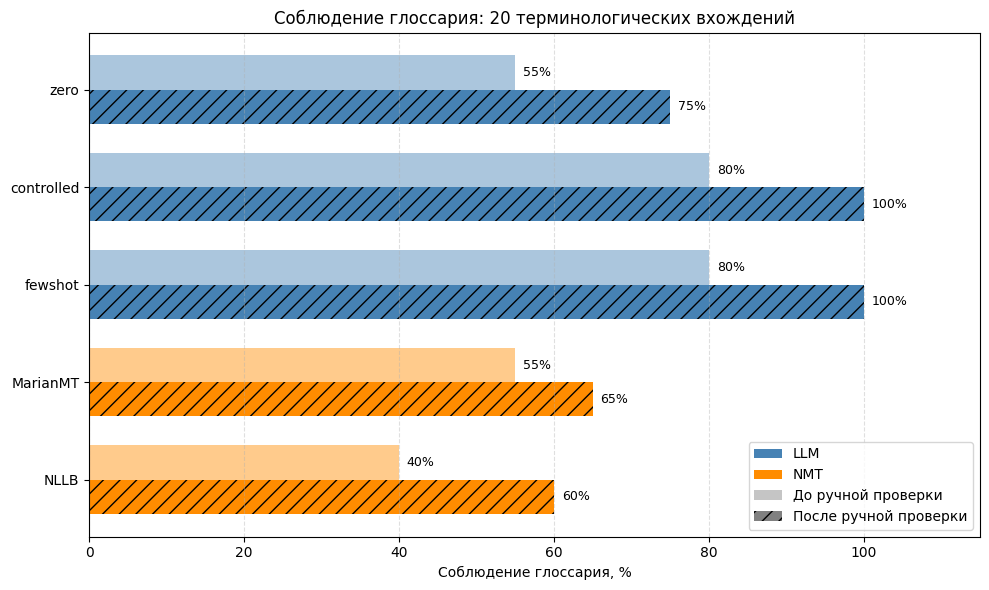

In [38]:
# 🧩 ЗАДАНИЕ А: диаграмма соблюдения глоссария (8–12 строк)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Данные из таблицы после ручной проверки
df = compliance_df.copy()
y = np.arange(len(df))
height = 0.35

# Разделяем системы по типу
colors = [
    "steelblue" if system in MODES else "darkorange"
    for system in df["system"]
]
fig, ax = plt.subplots(figsize=(10, 6))

# До ручной проверки
bars_before = ax.barh(
    y - height / 2,
    df["compliance_auto_%"],
    height,
    color=colors,
    alpha=0.45,
    label="До ручной проверки"
)

# После ручной проверки
bars_after = ax.barh(
    y + height / 2,
    df["compliance_checked_%"],
    height,
    color=colors,
    hatch="//",
    label="После ручной проверки"
)

# Подписи значений
for bars in [bars_before, bars_after]:
    for bar in bars:
        value = bar.get_width()
        ax.text(
            value + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.0f}%",
            va="center",
            fontsize=9
        )

ax.set_yticks(y)
ax.set_yticklabels(df["system"])
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xlabel("Соблюдение глоссария, %")
ax.set_title(
    f"Соблюдение глоссария: "
    f"{int(df['occurrences'].iloc[0])} терминологических вхождений"
)

# Легенда
legend_elements = [
    Patch(facecolor="steelblue", label="LLM"),
    Patch(facecolor="darkorange", label="NMT"),
    Patch(facecolor="gray", alpha=0.45,
          label="До ручной проверки"),
    Patch(facecolor="gray", hatch="//",
          label="После ручной проверки")
]

ax.legend(handles=legend_elements, loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
fig.savefig(
    FIGURES / "terminology_compliance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
# ваш код: рисунок по compliance_df и сохранение в FIGURES / "terminology_compliance.png"

## Блок 9. Разметка, числа, код, модальность и алфавит ▶

**Зачем.** В учебном тексте часть элементов нельзя переводить или менять. Проверочные случаи строятся из
ваших сегментов: выделение термина `**…**`, список из двух сегментов и фрагмент кода с числом и путём к
файлу. Отдельно проверяется модальность (*must*, *should*, *require*) и **алфавит**: слова, в которых
смешаны латиница и кириллица («датalink»), и непереведённые английские слова. Такие ошибки проходят и
проверку «кириллицы не меньше 50 %», и терминологическую QA, если слова нет в глоссарии.

**На что смотреть.** Четыре флага разметки (`True` — сохранено), таблицу модальности и таблицу слов со
смешанным алфавитом и латиницей по системам — это готовые примеры для экспертного разбора в блоке 12.

In [39]:
# ============================================================================
#  Блок 9. Разметка, числа, код, модальность и смешение алфавитов
# ============================================================================
def markup_cases() -> List[Dict[str, str]]:
    with_terms = [sid for sid in TEST_IDS if relevant_terms(SRC_BY_ID[sid])]
    base = (with_terms + [sid for sid in TEST_IDS if sid not in with_terms])[:3]
    base = (base * 3)[:3]                       # на случай очень маленького корпуса
    sid = base[0]
    terms_here = relevant_terms(SRC_BY_ID[sid])
    term_en, term_ru = terms_here[0] if terms_here else (SRC_BY_ID[sid].split()[1], "—")
    return [
        {"case": "bold", "segment_id": sid,
         "source": re.sub(re.escape(term_en), f"**{term_en}**", SRC_BY_ID[sid], count=1, flags=re.I),
         "expected": f"термин «{term_ru}» выделен **…**"},
        {"case": "list", "segment_id": base[1],
         "source": f"- {SRC_BY_ID[base[1]]}\n- {SRC_BY_ID[base[2]]}",
         "expected": "два пункта списка, маркеры «- » сохранены"},
        {"case": "code", "segment_id": base[0],
         "source": SRC_BY_ID[base[0]] + " Set `MAX_RATE = 200` in `config/params.yaml`.",
         "expected": "фрагменты в `…` не изменены"},
    ]


def markup_report(source: str, translation: str) -> Dict[str, Any]:
    code_src, code_tgt = re.findall(r"`[^`]+`", source), re.findall(r"`[^`]+`", translation)
    nums_src = re.findall(r"\d+(?:[.,]\d+)?", source)
    nums_tgt = re.findall(r"\d+(?:[.,]\d+)?", translation)
    return {"bold_ok": source.count("**") == translation.count("**"),
            "list_ok": len(re.findall(r"^- ", source, re.M)) == len(re.findall(r"^- ", translation, re.M)),
            "code_ok": code_src == code_tgt,
            "numbers_ok": sorted(n.replace(",", ".") for n in nums_src)
                          == sorted(n.replace(",", ".") for n in nums_tgt)}


markup_rows = []
for case in markup_cases():
    record = translate(case["segment_id"], case["source"], "controlled")
    record["mode"] = f"markup_{case['case']}"
    records.append(record)
    markup_rows.append({"case": case["case"], "segment_id": case["segment_id"],
                        "source": case["source"], "translation": record["translation"],
                        **markup_report(case["source"], record["translation"])})
markup_df = pd.DataFrame(markup_rows)
markup_df.to_csv(RESULTS / "markup_checks.csv", index=False, encoding="utf-8-sig")
print("Разметка (режим controlled):")
print(markup_df[["case", "bold_ok", "list_ok", "code_ok", "numbers_ok"]].to_string(index=False))

# --- модальность -----------------------------------------------------------------------
MODAL_EN = r"\b(must|should|can|cannot|may|need to|requires?|required)\b"
MODAL_RU = r"(должн|следует|может|могут|можно|нельзя|необходим|нужно|требу)"
modality = []
for sid in TEST_IDS:
    match = re.search(MODAL_EN, SRC_BY_ID[sid], re.I)
    if match:
        for system, table in systems.items():
            modality.append({"segment_id": sid, "system": system, "modal_en": match.group(0),
                             "preserved": bool(re.search(MODAL_RU, table.get(sid, ""), re.I)),
                             "translation": table.get(sid, "")})
modality_df = pd.DataFrame(modality, columns=["segment_id", "system", "modal_en", "preserved", "translation"])
print(f"\nСегментов с модальностью: {modality_df['segment_id'].nunique()}")
if len(modality_df):
    print(modality_df[["segment_id", "system", "modal_en", "preserved"]].to_string(index=False))


# --- смешение алфавитов и непереведённые слова -------------------------------------------
def script_issues(text: str) -> Tuple[List[str], List[str]]:
    plain = re.sub(r"`[^`]+`", " ", text or "")           # код в обратных кавычках не учитываем
    tokens = re.findall(r"[A-Za-zА-Яа-яЁё]+", plain)
    mixed = [t for t in tokens if re.search(r"[A-Za-z]", t) and re.search(r"[А-Яа-яЁё]", t)]
    latin = [t for t in tokens if re.fullmatch(r"[A-Za-z]+", t)]
    return mixed, latin


script_rows = []
for system, table in systems.items():
    for sid in TEST_IDS:
        mixed, latin = script_issues(table.get(sid, ""))
        if mixed or latin:
            script_rows.append({"segment_id": sid, "system": system, "mixed_words": len(mixed),
                                "latin_words": len(latin), "words": ", ".join(mixed + latin),
                                "translation": table.get(sid, "")})
script_df = pd.DataFrame(script_rows, columns=["segment_id", "system", "mixed_words", "latin_words",
                                               "words", "translation"])
script_summary = (script_df.groupby("system")[["mixed_words", "latin_words"]].sum()
                  .reindex(list(systems), fill_value=0))
print("\nСмешанный алфавит и латиница в переводах (тестовые сегменты):")
print(script_summary.to_string())
if len(script_df):
    print("\nПримеры:")
    print(script_df[["segment_id", "system", "words"]].head(10).to_string(index=False))

Разметка (режим controlled):
case  bold_ok  list_ok  code_ok  numbers_ok
bold     True     True     True        True
list     True     True     True        True
code     True     True     True        True

Сегментов с модальностью: 2
segment_id     system modal_en  preserved
      s003       zero requires       True
      s003 controlled requires       True
      s003    fewshot requires       True
      s003   MarianMT requires       True
      s003       NLLB requires       True
      s008       zero      can       True
      s008 controlled      can       True
      s008    fewshot      can       True
      s008   MarianMT      can       True
      s008       NLLB      can       True

Смешанный алфавит и латиница в переводах (тестовые сегменты):
            mixed_words  latin_words
system                              
zero                  0            1
controlled            0            3
fewshot               0            4
MarianMT              0            2
NLLB               

#### 🔎 Как читать результат

* `bold_ok`, `list_ok`, `code_ok`, `numbers_ok`: `True` — сохранено, `False` — потеряно. В эталоне модель
  сохранила код, числа и список, но потеряла выделение `**…**`.
* Модальность: `preserved = True` — обязательность действия передана («требуется», «должен»). Её потеря в
  инструкции меняет смысл требования.
* Смешанный алфавит («датalink») и латиница — ошибки, которые пропускают все остальные проверки.

## Блок 10. Targeted repair ▶

**Зачем.** Показать, что нарушение можно исправить **точечно**, не переводя сегмент заново. Для сегментов
с нарушениями отправляется узкая инструкция со списком «английский термин → обязательный эквивалент».

**Откуда берутся случаи.** Сначала из лучших режимов (few-shot, controlled), затем из zero-shot. Если у
LLM нарушений меньше трёх, исправляются переводы MarianMT и NLLB из ЛР № 2: LLM работает как
пост-редактор NMT.

**Двойной контроль.** После исправления заново считается число нарушений, а `unchanged_ratio` — доля
неизменённого текста (сходство строк до и после) — показывает, не переписала ли модель перевод целиком:
около 0,9 — точечная правка, ниже 0,7 — фактически новый перевод.

In [40]:
# ============================================================================
#  Блок 10. Targeted repair: узкое исправление только найденных нарушений
# ============================================================================
PRIORITY = ["fewshot", "controlled", "zero"] + [
    s for s in ("MarianMT", "NLLB") if s in systems
]
# Оставляем только нарушения, подтвержденные вручную как реальные
confirmed_errors = set(
    zip(
        terminology_qa.loc[
            terminology_qa["confirmed"] == "yes", "segment_id"
        ],
        terminology_qa.loc[
            terminology_qa["confirmed"] == "yes", "system"
        ],
        terminology_qa.loc[
            terminology_qa["confirmed"] == "yes", "source_term"
        ]
    )
)
candidates = []
for mode in PRIORITY:
    for sid in TEST_IDS:
        violations = term_violations(
            SRC_BY_ID[sid],
            systems[mode].get(sid, "")
        )

        # Убираем ложные срабатывания
        real_violations = [
            v for v in violations
            if (sid, mode, v["source_term"]) in confirmed_errors
        ]

        if real_violations:
            candidates.append((mode, sid, real_violations))
print(
    f"Сегментов с подтвержденными нарушениями: {len(candidates)}"
)
repair_rows = []
for mode, sid, found_violations in candidates[: max(N_REPAIR_MIN, 5)]:
    before = systems[mode][sid]
    prompt = REPAIR_TEMPLATE.format(
        segment_id=sid, source=SRC_BY_ID[sid], translation=before,
        violations="\n".join(f"- {v['source_term']} → {v['expected']}" for v in found_violations))
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    record = translate(sid, SRC_BY_ID[sid], f"repair_{mode}", messages=messages)
    records.append(record)
    after = record["translation"] or before
    remaining = term_violations(SRC_BY_ID[sid], after)
    repair_rows.append({
        "segment_id": sid, "mode": mode,
        "violations_before": len(found_violations), "violations_after": len(remaining),
        "unchanged_ratio": round(difflib.SequenceMatcher(None, before, after).ratio(), 3),
        "before": before, "after": after,
        "terms": "; ".join(v["source_term"] for v in found_violations)})

repair_df = pd.DataFrame(repair_rows, columns=["segment_id", "mode", "violations_before", "violations_after",
                                               "unchanged_ratio", "before", "after", "terms"])
repair_df.to_csv(RESULTS / "repair_cases.csv", index=False, encoding="utf-8-sig")
if len(repair_df):
    print(f"Нарушений до repair: {repair_df['violations_before'].sum()}, "
          f"после: {repair_df['violations_after'].sum()}; "
          f"средняя доля неизменённого текста: {repair_df['unchanged_ratio'].mean():.2f}\n")
    for row in repair_df.itertuples(index=False):
        print(f"[{row.segment_id} · {row.mode}] ratio={row.unchanged_ratio}\n  до   : {row.before}\n"
              f"  после: {row.after}")
else:
    print("Нарушений нет — repair не потребовался. Отметьте это в отчёте.")
repair_df.drop(columns=["before", "after"])

Сегментов с подтвержденными нарушениями: 13
Нарушений до repair: 7, после: 5; средняя доля неизменённого текста: 0.86

[s001 · zero] ratio=0.954
  до   : Интегрированный комплекс повысит эффективность и конкурентоспособность российской атомной промышленности и сделает атомную энергию еще более безопасной и экологически чистой.
  после: Интегрированный комплекс повысит эффективность и конкурентоспособность российской ядерной промышленности и сделает ядерную энергию еще более безопасной и экологически чистой.
[s007 · zero] ratio=0.828
  до   : Поэтому его помещают в водоемы или в сухие хранилища для охлаждения.
  после: Поэтому его помещают в бассейны для хранения в воде или в сухие хранилища для охлаждения.
[s008 · zero] ratio=0.899
  до   : До начала строительства объекта для утилизации компания, отвечающая за реализацию концепции, должна получить строительную лицензию.
  после: До начала строительства пункта захоронения компания, отвечающая за реализацию концепции, должна получить стр

,segment_id,mode,violations_before,violations_after,unchanged_ratio,terms
0,s001,zero,1,0,0.954,nuclear
1,s007,zero,2,2,0.828,dry storage; storage
2,s008,zero,1,0,0.899,disposal facility
3,s011,zero,1,1,0.913,exempt waste
4,s007,MarianMT,2,2,0.713,dry storage; storage


#### 🔎 Как читать результат

* Хороший repair: `violations_after` = 0 при высоком `unchanged_ratio`.
* `unchanged_ratio` считает совпадение **по буквам**. Замена короткого слова длинным термином («трубка Пито» →
  «приёмник воздушного давления») сама снижает его до ~0,75, хотя остальной текст не тронут. Поэтому
  обязательно сравните строки «до» и «после» глазами.
* Repair исправляет только названные термины: кальки, плеоназмы и ошибки вне глоссария остаются — найдите их
  и упомяните в выводах.

### 🧩 Задание Б. Эффект точечного исправления

**Цель.** Показать на одном рисунке два результата repair: **исправлены ли термины** и **не переписан ли
перевод целиком**.

**Данные:** `repair_df` — по строке на случай repair.

| Колонка | Смысл |
|---|---|
| `segment_id`, `mode` | какой перевод исправлялся |
| `violations_before`, `violations_after` | нарушения глоссария до и после |
| `unchanged_ratio` | доля неизменённого текста (1 — без изменений) |

**Требования к рисунку.**
1. Два графика рядом (`plt.subplots(1, 2)`): слева — сгруппированные столбцы нарушений до/после по
   случаям; справа — горизонтальные столбцы `unchanged_ratio`.
2. На правом графике вертикальные линии порогов 0,7 и 0,9 (`axis.axvline`) с подписью в легенде.
3. Подписи случаев в виде `s003 · zero`; общий заголовок с итогом «нарушений X → Y».
4. Сохранить в `FIGURES / "repair_effect.png"`.

**Что записать в выводы.** Какие случаи — точечная правка, какие — новый перевод; какие термины не удалось
исправить и почему (чаще всего многословный термин, требующий согласования по падежу).

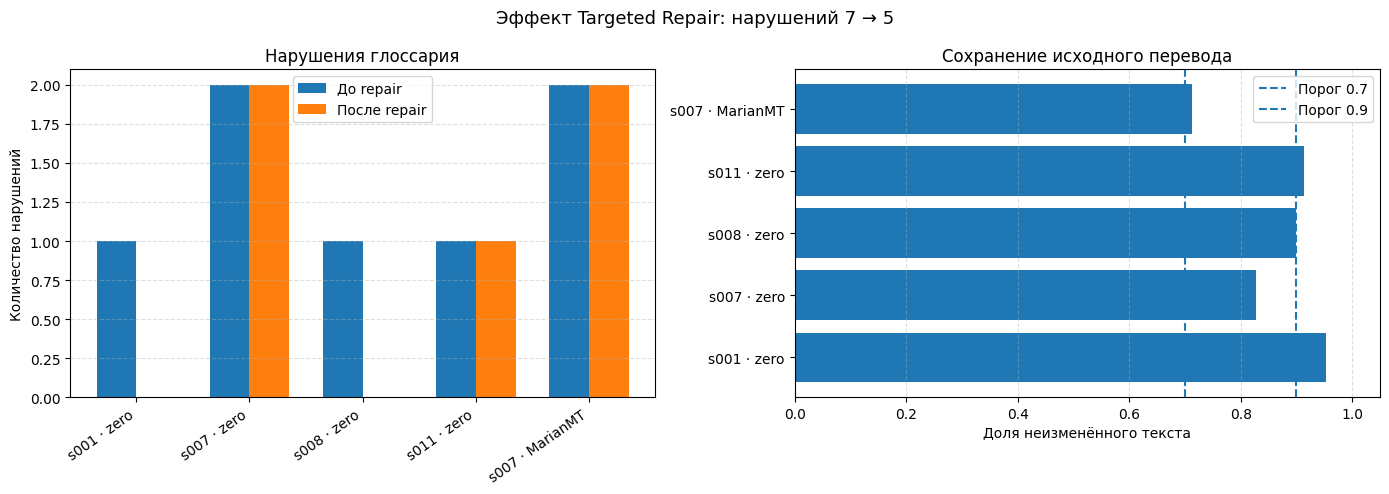

In [42]:

# 🧩 ЗАДАНИЕ Б. Эффект точечного исправления (Targeted Repair)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Берём результаты блока 10
repair_df = pd.read_csv(RESULTS / "repair_cases.csv")

# Подписи случаев
labels = repair_df["segment_id"] + " · " + repair_df["mode"]
x = np.arange(len(repair_df))
width = 0.35

# Два графика рядом
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ЛЕВЫЙ ГРАФИК: нарушения до и после repair
ax1.bar(
    x - width / 2,
    repair_df["violations_before"],
    width,
    label="До repair"
)

ax1.bar(
    x + width / 2,
    repair_df["violations_after"],
    width,
    label="После repair"
)

ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=35, ha="right")
ax1.set_ylabel("Количество нарушений")
ax1.set_title("Нарушения глоссария")
ax1.legend()
ax1.grid(axis="y", linestyle="--", alpha=0.4)

# ПРАВЫЙ ГРАФИК: доля неизменённого текста
ax2.barh(
    labels,
    repair_df["unchanged_ratio"]
)

ax2.axvline(
    0.7,
    linestyle="--",
    label="Порог 0.7"
)

ax2.axvline(
    0.9,
    linestyle="--",
    label="Порог 0.9"
)

ax2.set_xlim(0, 1.05)
ax2.set_xlabel("Доля неизменённого текста")
ax2.set_title("Сохранение исходного перевода")
ax2.legend()
ax2.grid(axis="x", linestyle="--", alpha=0.4)

# Общий заголовок
before_total = int(repair_df["violations_before"].sum())
after_total = int(repair_df["violations_after"].sum())

fig.suptitle(
    f"Эффект Targeted Repair: нарушений {before_total} → {after_total}",
    fontsize=13
)

plt.tight_layout()

# Сохранение рисунка
fig.savefig(
    FIGURES / "repair_effect.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## Блок 11. Управление стилем ▶

**Зачем.** Один и тот же сегмент переводится в академическом стиле (A) и в стиле преподавателя,
объясняющего первокурснику (B). Для педагога это ключевая возможность LLM: текст адаптируется под
аудиторию, **а терминология остаётся прежней**.

**Что считает код.** Простые признаки стиля: обращения на «вы», побудительные формы («проверьте»),
безличные и пассивные конструкции («калибруется»), число слов — и число нарушений глоссария в каждом стиле.

**Обратите внимание.** Стиль B превращает описание («оператор проверяет») в обращение к читателю. Это
меняет не только стиль, но и коммуникативную установку текста — хороший предмет для обсуждения в выводах:
где кончается стиль и начинается изменение смысла.

In [43]:
# ============================================================================
#  Блок 11. Управление стилем: академический (A) и инструктивный (B)
# ============================================================================
def style_metrics(text: str) -> Dict[str, Any]:
    tokens = re.findall(r"[\wёЁ-]+", text)
    return {"words": len(tokens),
            "you_forms": len(re.findall(r"\b(вы|вам|вас|ваш\w*)\b", text, re.I)),
            "imperatives": len(re.findall(r"\b\w+(?:ите|йте)\b", text, re.I)),
            "passive_or_impersonal": len(re.findall(r"\b\w+(?:ется|ются|ится|ятся)\b", text, re.I))}


style_ids = [sid for sid in TEST_IDS
             if re.search(r"\b(operator|before|check|upload|calibrat)", SRC_BY_ID[sid], re.I)]
style_ids = (style_ids + [sid for sid in TEST_IDS if sid not in style_ids])[:N_STYLE]
style_rows = []
for sid in style_ids:
    row = {"segment_id": sid, "source": SRC_BY_ID[sid]}
    for style in ("A", "B"):
        record = translate(sid, SRC_BY_ID[sid], f"style_{style}", style=style)
        records.append(record)
        row[f"style_{style}"] = record["translation"]
        row.update({f"{k}_{style}": v for k, v in style_metrics(record["translation"]).items()})
        row[f"violations_{style}"] = len(term_violations(SRC_BY_ID[sid], record["translation"]))
    style_rows.append(row)
style_df = pd.DataFrame(style_rows)
style_df.to_csv(RESULTS / "style_comparison.csv", index=False, encoding="utf-8-sig")
for row in style_rows:
    print(f"[{row['segment_id']}] {row['source']}\n  A: {row['style_A']}\n  B: {row['style_B']}\n")
style_df.drop(columns=["source", "style_A", "style_B"])

[s008] Before construction of a disposal facility can begin, the company in charge of implementing the concept needs to obtain a construction licence.
  A: До начала строительства пункта захоронения компания, отвечающая за реализацию концепции, должна получить лицензию на строительство.
  B: Прежде чем начать строительство пункта захоронения, компании, ответственной за реализацию концепции, необходимо получить строительную лицензию.

[s001] The integrated complex will improve the efficiency and competitiveness of the Russian nuclear industry and make nuclear energy even safer and more environmentally friendly.
  A: Интегрированный комплекс повысит эффективность и конкурентоспособность российской ядерной промышленности и сделает ядерную энергию еще более безопасной и экологически чистой.
  B: Интегрированный комплекс повысит эффективность и конкурентоспособность российской ядерной промышленности и сделает ядерную энергию ещё более безопасной и экологически чистой.

[s002] Previously, Ru

,segment_id,words_A,you_forms_A,imperatives_A,passive_or_impersonal_A,violations_A,words_B,you_forms_B,imperatives_B,passive_or_impersonal_B,violations_B
0,s008,15,0,0,0,0,15,0,0,0,0
1,s001,19,0,0,0,0,19,0,0,0,0
2,s002,32,0,0,0,0,32,0,0,0,0


#### 🔎 Как читать результат

Сравните строки A и B: появилось ли обращение на «вы» или побуждение в B, безличные и пассивные
конструкции в A? В эталоне стиль сработал в 1 из 3 сегментов: «Перед взлётом **вы** проверяете…». Обратите
внимание, совпала ли терминология (`violations_A` и `violations_B`) и не превратилось ли описание в инструкцию —
это уже изменение смысла, а не стиля.

### 🧩 Задание В. Чем различаются стили A и B

**Цель.** Показать, что стиль управляем (или нет), а терминология при смене стиля не страдает.

**Данные:** `style_df` — по строке на сегмент; для каждого стиля (`_A`, `_B`) колонки `words`,
`you_forms`, `imperatives`, `passive_or_impersonal`, `violations`.

**Требования.**
1. Сумма каждого признака по всем сегментам для A и для B: таблица 2 × 5 (подсказка: выберите колонки с
   окончанием `_A`, просуммируйте, уберите суффикс; так же для `_B`; объедините в `pd.DataFrame`).
2. Сгруппированная столбчатая диаграмма признаков A против B (кроме `words` — у неё другой масштаб).
3. Подписи осей и заголовок; сохранить в `FIGURES / "style_markers.png"`.
4. Таблицу назовите `style_totals` и выведите её последней строкой ячейки.

**Что записать в выводы.** Есть ли в B обращения и побуждения, а в A — безличные конструкции; совпала ли
терминология в обоих стилях; не изменил ли стиль B модальность исходника.

Суммарные показатели стилей:


,words,you_forms,imperatives,passive_or_impersonal,violations
Стиль A,66,0,0,0,0
Стиль B,66,0,0,1,0


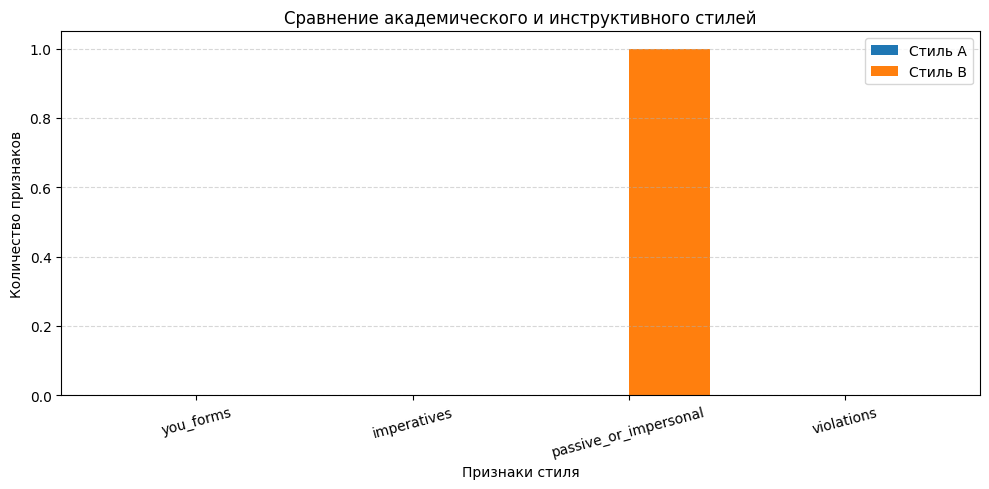

График сохранён: style_markers.png


,words,you_forms,imperatives,passive_or_impersonal,violations
Стиль A,66,0,0,0,0
Стиль B,66,0,0,1,0


In [44]:

# 🧩 ЗАДАНИЕ В. Сравнение стилей A и B

import matplotlib.pyplot as plt
import pandas as pd
import re
import numpy as np
# Загружаем результаты неизменённого блока 11
style_df = pd.read_csv(
    "/content/lab03/results/style_comparison.csv"
)

# Более точный подсчёт признаков по самим переводам
def count_style_features(text):
    text = str(text)

    words = len(re.findall(r"[\wёЁ-]+", text))

    you_forms = len(re.findall(
        r"\b(вы|вам|вас|ваш\w*)\b",
        text, re.I
    ))

    imperatives = len(re.findall(
        r"\b\w+(?:ите|йте|ись|итесь)\b",
        text, re.I
    ))

    # Безличные конструкции и краткие страдательные причастия
    impersonal = len(re.findall(
        r"\b(необходимо|следует|требуется|можно|нужно)\b",
        text, re.I
    ))

    passive = len(re.findall(
        r"\b(был|была|было|были)\s+"
        r"\w+(?:н|т)(?:ый|ая|ое|ые|ого|ой|ых|ому|ым|ую)?\b",
        text, re.I
    ))

    return {
        "words": words,
        "you_forms": you_forms,
        "imperatives": imperatives,
        "passive_or_impersonal": impersonal + passive
    }


# Пересчитываем показатели непосредственно по текстам A и B
for style in ("A", "B"):
    metrics = style_df[f"style_{style}"].apply(count_style_features)

    for metric in metrics.iloc[0].keys():
        style_df[f"{metric}_{style}"] = [
            item[metric] for item in metrics
        ]

# Формируем таблицу 2 × 5
metrics_names = [
    "words",
    "you_forms",
    "imperatives",
    "passive_or_impersonal",
    "violations"
]
style_totals = pd.DataFrame(
    {
        metric: [
            style_df[f"{metric}_A"].sum(),
            style_df[f"{metric}_B"].sum()
        ]
        for metric in metrics_names
    },
    index=["Стиль A", "Стиль B"]
)

print("Суммарные показатели стилей:")
display(style_totals)

# Строим диаграмму без words, поскольку у него другой масштаб
plot_metrics = [
    "you_forms",
    "imperatives",
    "passive_or_impersonal",
    "violations"
]
ax = style_totals[plot_metrics].T.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_xlabel("Признаки стиля")
ax.set_ylabel("Количество признаков")
ax.set_title("Сравнение академического и инструктивного стилей")
ax.legend(["Стиль A", "Стиль B"])
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "/content/lab03/figures/style_markers.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
print("График сохранён: style_markers.png")
# Последняя строка — обязательная таблица
style_totals


## Блок 12. Сводная таблица и экспертные решения

**Зачем.** Свести эталон ЛР № 1, переводы NMT из ЛР № 2 и три режима LLM в одну таблицу и принять по
сегментам экспертные решения. Типы различий — как в ЛР № 2 (по MQM): **точность**, **терминология**,
**беглость**, **стиль**, **разметка**.

**Ячейка ниже печатает все 12 сегментов** со всеми переводами и пометками: ⚑ — нарушение глоссария,
✳ — смешанный алфавит или латиница. Прочитайте их перед тем, как заполнять `EXPERT`.

In [45]:
# ============================================================================
#  Блок 12. Сводная таблица переводов
# ============================================================================
comparison = pd.DataFrame({"segment_id": TEST_IDS,
                           "source": [SRC_BY_ID[s] for s in TEST_IDS],
                           "reference": [REF_BY_ID[s] for s in TEST_IDS]})
for system, table in systems.items():
    comparison[system] = [table.get(sid, "") for sid in TEST_IDS]

for row in comparison.to_dict("records"):
    print(f"[{row['segment_id']}] {row['source']}")
    print(f"  {'эталон':<11}: {row['reference']}")
    for system in systems:
        text = row[system]
        flags = ("⚑" if term_violations(row["source"], text) else " ") + \
                ("✳" if any(script_issues(text)) else " ")
        print(f"  {system:<11}{flags}: {text}")
    print()

[s001] The integrated complex will improve the efficiency and competitiveness of the Russian nuclear industry and make nuclear energy even safer and more environmentally friendly.
  эталон     : Интегрированный комбинат позволит повысить эффективность и конкурентоспособность российской атомной отрасли и сделать атомную энергетику еще более безопасной и экологичной.
  zero       ⚑ : Интегрированный комплекс повысит эффективность и конкурентоспособность российской атомной промышленности и сделает атомную энергию еще более безопасной и экологически чистой.
  controlled   : Интегрированный комплекс повысит эффективность и конкурентоспособность российской ядерной промышленности и сделает ядерную энергию еще более безопасной и экологически чистой.
  fewshot      : Интегрированный комплекс повысит эффективность и конкурентоспособность российской ядерной промышленности и сделает ядерную энергию еще более безопасной и экологически чистой.
  MarianMT     : Комплексный комплекс повысит эффективно

#### 🔎 Как читать результат

⚑ — отклонение от глоссария, ✳ — смешанный алфавит или латиница. **Отсутствие флажка не значит, что перевод
верен.** Читайте все переводы и ищите то, что автоматическая проверка не видит. Примеры из эталона:
* калька вне глоссария: *indicated airspeed* → «показанной скорости» (норма — «приборная скорость»);
* смысловая ошибка без флажка: *stall* → «задержка» вместо «сваливание»;
* сужение значения: *aircraft* → «самолёт» вместо «аппарат»;
* повтор и калька: «Операции полёта… разрешения на полёт».

Эти находки — лучший материал для `EXPERT` и выводов.

### Блок 12.1. ✏️ Экспертные решения (минимум 5 сегментов)

Для каждого выбранного сегмента укажите, какой перевод предпочтительнее, и **аргументируйте с типом
различия**. Хорошее решение называет конкретное слово и тип ошибки у остальных систем.

| Хорошо | Плохо |
|---|---|
| `("fewshot", "Терминология: только few-shot сохраняет «планёр»; zero — бытовое «кузов самолёта», MarianMT — смысловая ошибка «воздушное пространство»")` | `("fewshot", "лучше всех")` |

Значение выбора: `"zero"`, `"controlled"`, `"fewshot"`, `"MarianMT"`, `"NLLB"` или `"ни один"`.
Решения записываются в колонки `preferred` и `comment` файла `results/comparison.csv`.

In [46]:
# ✏️ ЗАПОЛНИТЬ: экспертные решения (минимум 5 сегментов)
EXPERT: Dict[str, Tuple[str, str]] = {
    "s001": ("controlled", "Терминология: controlled и fewshot используют «ядерная промышленность» и «ядерная энергия», что соответствует эквиваленту nuclear из TBX. Zero использует «атомная промышленность» и «атомная энергия». MarianMT допускает тавтологию «комплексный комплекс». Переводы controlled и fewshot практически идентичны."),
    "s002": ("controlled", "Грамматика и смысл: zero и NMT потеряли смысл (например, NLLB написала 'Ассоциация по производству Майак' вместо 'ПО «Маяк»', а zero написала 'отработавшие ядерное топливо' с ошибкой согласования)."),
    "s006": ("controlled", "Аббревиатуры: LLM в режимах controlled и fewshot корректно оставила латиницу HEU/LEU, тогда как NLLB перевела их описательно ('топливо с высоким обогащением урана'), что нарушает нормы научного стиля."),
    "s007": ("controlled", "Терминология: controlled и fewshot передали dry storage как «объекты сухого хранения», что соответствует термину из TBX. Zero, MarianMT и NLLB использовали «сухие хранилища», что не соответствует установленному эквиваленту. Controlled выбран как предпочтительный вариант."),
    "s011": ("controlled", "Грубая ошибка NMT: MarianMT перевела 'clearance criteria' как 'критерии разминирования' (сапёрная тематика), NLLB написала 'освобожденная от отходов'. LLM справилась с переводом 'изъятые отходы' (в controlled/fewshot)."),
    "s012": ("fewshot", "Смысловая точность: zero исказил 'fracture network' до 'трещиноватой сети', MarianMT выдала 'в случае безопасного хранилища' вместо 'в обосновании безопасности'. Fewshot дал наиболее точный перевод 'в сети трещин'.")
}
comparison["preferred"] = ""
comparison["comment"] = ""
for sid, (choice, note) in EXPERT.items():
    comparison.loc[comparison["segment_id"] == sid, ["preferred", "comment"]] = [choice, note]
comparison.to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")
filled = int(((comparison["preferred"] != "") & (comparison["comment"].str.len() > 10)).sum())
print(f"Экспертных решений с аргументом: {filled} (требуется ≥ 5)")

Экспертных решений с аргументом: 6 (требуется ≥ 5)


### 🧩 Задание Г. Сводная таблица систем

**Цель.** Одна таблица, по которой видно, чем отличаются системы: формат, скорость, терминология, алфавит,
близость к эталону. Она войдёт в отчёт и станет опорой для выводов.

**Данные, которые уже есть.**

| Объект | Что в нём |
|---|---|
| `systems` | словарь «система → {segment_id: перевод}» (режимы LLM и NMT) |
| `runs` | трассировка блока 7: колонки `mode`, `json_valid`, `attempts`, `latency_s` (только LLM) |
| `compliance_df` | `violations_auto`, `false_positives`, `violations_checked`, `compliance_checked_%` |
| `script_summary` | `mixed_words`, `latin_words` по системам (индекс — система) |
| `REF_BY_ID`, `TEST_IDS` | эталон ЛР № 1 и тестовые сегменты |

**Требования.** Таблица `mode_summary`, по строке на систему, колонки:

| Колонка | Как получить |
|---|---|
| `system`, `type` | имя системы; `"LLM"` для режимов из `MODES`, иначе `"NMT"` |
| `json_valid_%`, `mean_latency_s` | из `runs` для режимов LLM; для NMT — `None` |
| `violations_checked`, `compliance_checked_%` | из `compliance_df` |
| `mixed_words`, `latin_words` | из `script_summary` |
| `length_ratio` | суммарная длина переводов / суммарная длина эталона (≈ 1 — без пропусков и добавлений) |
| `same_as_reference` | число сегментов, где перевод совпал с эталоном без учёта регистра и знаков препинания |

Сохраните таблицу в `RESULTS / "mode_summary.csv"` и выведите её последней строкой ячейки.

**Подсказка.** Собирайте список словарей в цикле `for system, table in systems.items():`, затем
`pd.DataFrame(rows)`. Для нормализации строк: `re.sub(r"\W+", " ", text.lower()).strip()`.

In [47]:

# ЗАДАНИЕ Г. Сводная таблица систем

import re
import pandas as pd
import matplotlib.pyplot as plt

def normalize_text(text):
    return re.sub(r"\W+", " ", str(text).lower()).strip()

rows = []

for system, table in systems.items():

    # Определяем тип системы
    system_type = "LLM" if system in MODES else "NMT"

    # Данные о JSON и скорости доступны только для LLM
    if system_type == "LLM":
        system_runs = runs[runs["mode"] == system]
        json_valid = round(system_runs["json_valid"].mean() * 100, 1)
        latency = round(system_runs["latency_s"].mean(), 2)
    else:
        json_valid = None
        latency = None

    # Терминологические показатели
    comp = compliance_df[compliance_df["system"] == system].iloc[0]

    # Смешанный алфавит и латиница
    mixed = int(script_summary.loc[system, "mixed_words"])
    latin = int(script_summary.loc[system, "latin_words"])

    # Близость длины перевода к эталону
    total_translation = sum(len(table.get(sid, "")) for sid in TEST_IDS)
    total_reference = sum(len(REF_BY_ID[sid]) for sid in TEST_IDS)

    length_ratio = round(
        total_translation / max(total_reference, 1), 3
    )

    # Количество совпадений с эталоном
    same_count = sum(
        normalize_text(table.get(sid, "")) ==
        normalize_text(REF_BY_ID[sid])
        for sid in TEST_IDS
    )

    rows.append({
        "system": system,
        "type": system_type,
        "json_valid_%": json_valid,
        "mean_latency_s": latency,
        "violations_checked": int(comp["violations_checked"]),
        "compliance_checked_%": comp["compliance_checked_%"],
        "mixed_words": mixed,
        "latin_words": latin,
        "length_ratio": length_ratio,
        "same_as_reference": same_count
    })

# Формируем обязательную таблицу
mode_summary = pd.DataFrame(rows)

# Сохраняем результат
mode_summary.to_csv(
    RESULTS / "mode_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ЗАДАНИЕ Г. СВОДНАЯ ТАБЛИЦА СИСТЕМ")
display(mode_summary)

print("\nТаблица mode_summary.csv сохранена.")


ЗАДАНИЕ Г. СВОДНАЯ ТАБЛИЦА СИСТЕМ


,system,type,json_valid_%,mean_latency_s,violations_checked,compliance_checked_%,mixed_words,latin_words,length_ratio,same_as_reference
0,zero,LLM,100.0,5.77,5,75.0,0,1,1.001,0
1,controlled,LLM,100.0,4.37,0,100.0,0,3,1.007,0
2,fewshot,LLM,100.0,3.63,0,100.0,0,4,1.010,0
3,MarianMT,NMT,NaN,NaN,7,65.0,0,2,0.997,0
4,NLLB,NMT,NaN,NaN,8,60.0,0,7,1.001,0



Таблица mode_summary.csv сохранена.


## Чек-лист сдачи ▶

Ячейка проверяет требования работы по тому, что уже сделано, и подсказывает, чего не хватает. ✅ —
выполнено, ❌ — не выполнено (в скобках — последствие по критериям оценивания). Модель не вызывается;
ячейку можно перезапускать после каждого исправления. Здесь же — самопроверка функций пайплайна.

In [48]:
# ============================================================================
#  Чек-лист сдачи и самопроверка функций
# ============================================================================
def _ok(condition: bool, text: str, consequence: str = "") -> bool:
    print(f"{'✅' if condition else '❌'} {text}" + ("" if condition or not consequence else f"  ({consequence})"))
    return bool(condition)


def _self_tests() -> List[str]:
    failed = []
    tests = {
        "relevant_terms": lambda: set(dict(relevant_terms(
            "The operator uploads a new waypoint to the autopilot.",
            pd.DataFrame({"en": ["waypoint", "autopilot", "airframe"],
                          "ru": ["путевая точка", "автопилот", "планёр"]})))) == {"waypoint", "autopilot"},
        "validate_response": lambda: (validate_response('{"segment_id": "s001", "translation": "Связь.", '
                                                        '"used_terms": [], "warnings": []}', "s001")[0] is not None
                                      and validate_response('{"segment_id": "s002", "translation": "Связь.", '
                                                            '"used_terms": [], "warnings": []}', "s001")[0] is None),
        "term_present": lambda: (term_present("наземная станция управления", "включает наземную станцию управления")
                                 and term_present("угол атаки", "превышение критического угла атаки")
                                 and not term_present("планёр", "стабилизирует воздушное пространство")),
        "markup_report": lambda: all(markup_report("Set `MAX_RATE = 200` in **flight**.",
                                                   "Задайте `MAX_RATE = 200` в **полёте**.").values()),
    }
    for name, test in tests.items():
        try:
            if not test():
                failed.append(name)
        except Exception as error:
            failed.append(f"{name}: {error}")
    return failed


main_runs = runs[runs["mode"].isin(MODES)]
failed_tests = _self_tests()
print("Пайплайн")
_ok(PROVIDER != "mock", f"реальная LLM: {PROVIDER} / {MODEL}", "mock — работа не засчитывается")
_ok(any(r.get("model_version") for r in records), "версия модели записана в трассировку", "−1")
_ok(all((main_runs["mode"] == m).sum() >= N_TEST for m in MODES),
    f"три режима по {N_TEST} одинаковых сегментов", "критерий «три режима»")
_ok(main_runs["json_valid"].all(), f"валидный JSON: {main_runs['json_valid'].mean():.0%} ответов")
_ok(not set(select_fewshot(SRC_BY_ID[TEST_IDS[0]])) & set(TEST_IDS), "few-shot не пересекается с тестом", "−2")
_ok(not failed_tests, "самопроверка функций пайплайна" + (f": {failed_tests}" if failed_tests else ""))

print("\nВаши решения и анализ")
if "VARIANT" in globals():
    _ok(bool(VARIANT) and bool(VARIANT_DOMAIN), "указаны вариант и предметная область (блок 2)")
described = [sid for sid in select_fewshot(SRC_BY_ID[TEST_IDS[0]]) if FEWSHOT_NOTES.get(sid, "").strip()]
_ok(len(described) >= 2, f"примеры few-shot описаны: {len(described)} (блок 3.1)", "снижает оценку анализа")
_ok((terminology_qa["confirmed"] != "").all(),
    f"QA подтверждена: {(terminology_qa['confirmed'] != '').sum()} из {len(terminology_qa)} (блок 8.1)",
    "ручные колонки не заполнены — −2")
_ok(len(repair_df) >= N_REPAIR_MIN, f"случаев repair: {len(repair_df)}", "критерий repair")
_ok(len(style_df) >= N_STYLE, f"стилистических сравнений: {len(style_df)}")
filled = int(((comparison["preferred"] != "") & (comparison["comment"].str.len() > 10)).sum())
_ok(filled >= 5, f"экспертных решений с аргументом: {filled} из 5 (блок 12.1)",
    "критерий «5+ различий»; ручные колонки — −2")
for label, name in (("А", "terminology_compliance.png"), ("Б", "repair_effect.png"), ("В", "style_markers.png")):
    _ok((FIGURES / name).exists(), f"задание {label}: figures/{name}", "критерий «режимы и стили»")
_ok(isinstance(globals().get("mode_summary"), pd.DataFrame) and len(globals()["mode_summary"]) >= 3,
    "задание Г: таблица mode_summary", "критерий «режимы и стили»")

print("\nСекреты")
secret_values = [v for v in (get_secret(n) for n in SECRET_NAMES) if v and len(v) >= 8]
leaks = [p for p in BASE.rglob("*") if p.is_file() and p.suffix in {".md", ".txt", ".json", ".jsonl", ".csv", ".py", ".ipynb"}
         and any(v in p.read_text(encoding="utf-8", errors="ignore") for v in secret_values)]
_ok(not leaks, "значения секретов не попали в файлы работы" + (f": {leaks}" if leaks else ""), "−4 и отзыв ключа")
print("\nНапоминание: перед публикацией в Git проверьте и историю коммитов — в ней не должно быть .env и ключей.")

Пайплайн
✅ реальная LLM: ollama / qwen3.5:9b
✅ версия модели записана в трассировку
✅ три режима по 12 одинаковых сегментов
✅ валидный JSON: 100% ответов
✅ few-shot не пересекается с тестом
✅ самопроверка функций пайплайна

Ваши решения и анализ
✅ указаны вариант и предметная область (блок 2)
✅ примеры few-shot описаны: 2 (блок 3.1)
✅ QA подтверждена: 38 из 38 (блок 8.1)
✅ случаев repair: 5
✅ стилистических сравнений: 3
✅ экспертных решений с аргументом: 6 из 5 (блок 12.1)
✅ задание А: figures/terminology_compliance.png
✅ задание Б: figures/repair_effect.png
✅ задание В: figures/style_markers.png
✅ задание Г: таблица mode_summary

Секреты
✅ значения секретов не попали в файлы работы

Напоминание: перед публикацией в Git проверьте и историю коммитов — в ней не должно быть .env и ключей.


## Блок 13. Отчёт, README, версии промптов и выгрузка ▶

**Зачем.** Собрать результаты по требованиям работы: `report.md` (10 разделов задания), `README.md`,
`prompt_versions.md`, `requirements.txt`, `.env.example` (только имена переменных), `.gitignore`, таблицы,
промпты и рисунки — и упаковать их в `lab03_results.zip`. Если подключён Drive, архив копируется в
`MyDrive/mt_course/lab03/`.

После архивации допишите выводы в блоке 14 (и при желании в `report.md`) — архив можно пересобрать,
перезапустив эту ячейку.

In [49]:
# ============================================================================
#  Блок 13. Отчёт, README, версии промптов, зависимости и выгрузка
# ============================================================================
from importlib import metadata


def md_table(frame: pd.DataFrame) -> str:
    columns = [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    for row in frame.itertuples(index=False):
        lines.append("| " + " | ".join("—" if v is None or (isinstance(v, float) and pd.isna(v))
                                       else str(v).replace("|", "/") for v in row) + " |")
    return "\n".join(lines)


def package_version(name: str) -> str:
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return ""


prompt_table = "\n".join(f"| `{name}` | `{prompt_hash(text)}` | {len(text)} |"
                         for name, text in PROMPT_REGISTRY.items())
(BASE / "prompt_versions.md").write_text(
    f"# Версии промптов\n\nВерсия набора: **{PROMPT_VERSION}** (v1.1 — уточнён стиль B)\n\n"
    f"| Промпт | sha256 (10 знаков) | Длина |\n|---|---|---:|\n{prompt_table}\n", encoding="utf-8")

packages = ["pydantic", "python-dotenv", "pandas", "matplotlib",
            {"ollama": "ollama", "gigachat": "gigachat", "yandex": "yandex-ai-studio-sdk"}.get(PROVIDER, "")]
(BASE / "requirements.txt").write_text(
    "\n".join(f"{p}=={package_version(p)}" if package_version(p) else p for p in packages if p) + "\n",
    encoding="utf-8")
(BASE / ".env.example").write_text("GIGACHAT_CREDENTIALS=\nGIGACHAT_SCOPE=GIGACHAT_API_PERS\nGIGACHAT_CA_BUNDLE=\n"
                                   "YANDEX_FOLDER_ID=\nYANDEX_API_KEY=\n", encoding="utf-8")
(BASE / ".gitignore").write_text(".env\n.venv/\n__pycache__/\n*.pyc\n*.cer\n*.crt\n", encoding="utf-8")

with open(RESULTS / "results_llm.jsonl", "w", encoding="utf-8") as handle:
    for record in records:
        handle.write(json.dumps(record, ensure_ascii=False) + "\n")

valid_share = runs.groupby("mode")["json_valid"].mean().mul(100).round(1).to_dict()
model_build = ENVIRONMENT.get("model_digest") or next((r["model_version"] for r in records if r.get("model_version")), "—")
expert_rows = comparison.loc[comparison["preferred"] != "", ["segment_id", "preferred", "comment"]]
summary_table = globals().get("mode_summary")
qa_confirmed = int((terminology_qa["confirmed"] != "").sum())
figures_list = "\n".join(f"- `figures/{p.name}`" for p in sorted(FIGURES.glob("*.png"))) or "- рисунков нет"
local_params = (f"- Параметры Ollama: think={OLLAMA_THINK}, num_ctx={OLLAMA_NUM_CTX}, "
                f"presence_penalty={OLLAMA_PRESENCE_PENALTY}; версия: {ENVIRONMENT.get('ollama_version', '—')}; "
                f"GPU: {ENVIRONMENT.get('gpu', '—')}\n") if PROVIDER == "ollama" else ""
auth = ("локальная модель, ключи не нужны" if PROVIDER == "ollama" else
        "ключи читаются из Colab Secrets / `.env`; в репозитории только `.env.example`")

markup_text = ", ".join(
    f"{row['case']}: " + ("сохранена" if all(row[k] for k in ("bold_ok", "list_ok", "code_ok", "numbers_ok"))
                          else "нарушена") for row in markup_rows)
modality_text = (f"{int(modality_df['preserved'].sum())} из {len(modality_df)} переводов сохранили модальность"
                 if len(modality_df) else "модальных сегментов нет")
script_text = ", ".join(f"{name}: {int(v.mixed_words)}/{int(v.latin_words)}" for name, v in script_summary.iterrows())
summary_block = ("Сводная таблица систем (задание Г):\n\n" + md_table(summary_table)
                 if isinstance(summary_table, pd.DataFrame) else "Сводная таблица систем (задание Г) не построена.")
mock_line = "- ⚠ Режим mock: модель не вызывалась, работа к сдаче не принимается" if PROVIDER == "mock" else ""
if len(repair_df):
    repair_text = (f"Случаев: {len(repair_df)}; нарушений до/после: {int(repair_df['violations_before'].sum())} / "
                   f"{int(repair_df['violations_after'].sum())}; средний unchanged_ratio: "
                   f"{repair_df['unchanged_ratio'].mean():.2f}. Подробно — `results/repair_cases.csv`.")
else:
    repair_text = "Нарушений для исправления не было."
expert_text = "\n".join(f"- **{r.segment_id}** → {r.preferred}: {r.comment}" for r in expert_rows.itertuples(index=False))

report = f"""# Отчёт по лабораторной работе 3 (вариант {VARIANT})

**Предметная область (сквозной кейс ЛР № 1–2):** {VARIANT_DOMAIN or DOMAIN_EN}
**Дата прогона:** {ENVIRONMENT['run_date']}

## 1–3. Модель, версия, авторизация
- Провайдер: `{PROVIDER}`, модель: `{MODEL}`, версия/сборка: `{model_build}`
- Параметры: temperature={TEMPERATURE}, seed={SEED}, max_tokens={MAX_TOKENS}
{local_params}- Авторизация: {auth}
{mock_line}

## 4–5. Системный промпт и JSON Schema
Версия промптов {PROMPT_VERSION}; тексты — `prompts/`, хэши — `prompt_versions.md`.
Схема: `prompts/translation_schema.json` (segment_id, translation, used_terms, warnings);
проверка: синтаксис JSON → Pydantic → segment_id, непустой перевод, доля кириллицы ≥ 50 %.

## 6. Режимы zero / controlled / few-shot ({len(TEST_IDS)} сегментов) и сравнение с NMT
Доля валидных JSON-ответов, %: {valid_share}

Соблюдение глоссария ({occurrences} вхождений терминов; ручных решений {qa_confirmed} из {len(terminology_qa)}):

{md_table(compliance_df)}

{summary_block}

Разметка (controlled): {markup_text}.
Модальность: {modality_text}.
Смешанный алфавит / латиница (смешанные/латинские слова): {script_text}.

Рисунки:
{figures_list}

## 7. Анализ ошибок
Экспертных решений: {len(expert_rows)}

{expert_text}

## 8. Terminology repair
{repair_text}

## 9. Стиль A / B
Сегментов: {len(style_df)}; нарушений глоссария A/B: {int(style_df['violations_A'].sum())} / {int(style_df['violations_B'].sum())}; см. `results/style_comparison.csv`.

## 10. Ограничения и вывод
Ограничения: {len(TEST_IDS)} сегментов, одна модель, temperature={TEMPERATURE}; терминологическая QA — эвристика с ручным подтверждением.

Вывод: см. блок 14 ноутбука.
"""
(BASE / "report.md").write_text(report, encoding="utf-8")

readme = f"""# ЛР № 3. Контекстный перевод и локализация с помощью LLM (вариант {VARIANT})

Управляемый LLM-пайплайн перевода: системная инструкция, термины сегмента из TBX, примеры few-shot из TMX,
JSON Schema + Pydantic, терминологическая QA, targeted repair, сравнение стилей и сравнение с NMT (ЛР № 2).

## Как воспроизвести
1. Открыть `LAB_03.ipynb` в Google Colab, среда — GPU T4.
2. Положить `variant_<N>.tmx`, `variant_<N>.tbx` и `lab02_results.zip` в `lab03/input/`.
3. Выполнить все ячейки. Модель: `{MODEL}` (`{PROVIDER}`), сборка `{model_build}`, temperature {TEMPERATURE}, seed {SEED}.
4. Для облачных моделей задать секреты по образцу `.env.example` (Colab Secrets или `.env`).

## Структура
- `prompts/` — промпты (версия {PROMPT_VERSION}, хэши в `prompt_versions.md`) и JSON Schema
- `results/` — трассировка `results_llm.jsonl`, `terminology_qa.csv`, `markup_checks.csv`, `repair_cases.csv`,
  `style_comparison.csv`, `comparison.csv`, `mode_summary.csv`
- `figures/` — рисунки анализа
- `report.md` — отчёт; `requirements.txt` — зависимости
"""
(BASE / "README.md").write_text(readme, encoding="utf-8")

archive = shutil.make_archive(str(BASE.parent / "lab03_results"), "zip", root_dir=BASE.parent, base_dir=BASE.name)
print("Созданные файлы (без input/ и data/):")
for path in sorted(BASE.rglob("*")):
    relative = path.relative_to(BASE)
    if path.is_file() and relative.parts[0] not in {"input", "data"}:
        print(f"  {str(relative):<40} {path.stat().st_size:>8} байт")
print("Архив:", archive)
if DRIVE_COURSE_DIR.is_dir():
    (DRIVE_COURSE_DIR / "lab03").mkdir(exist_ok=True)
    shutil.copy2(archive, DRIVE_COURSE_DIR / "lab03" / "lab03_results.zip")
    print("Копия на Drive:", DRIVE_COURSE_DIR / "lab03" / "lab03_results.zip")
try:
    from google.colab import files
    files.download(archive)
except Exception:
    pass

Созданные файлы (без input/ и data/):
  .env.example                                  109 байт
  .gitignore                                     43 байт
  README.md                                    1371 байт
  figures/repair_effect.png                  103109 байт
  figures/style_markers.png                   59822 байт
  figures/terminology_compliance.png          79126 байт
  prompt_versions.md                            384 байт
  prompts/fewshot.json                         2443 байт
  prompts/prompt_repair.txt                     787 байт
  prompts/prompt_system.txt                    1632 байт
  prompts/repair.txt                            787 байт
  prompts/system_controlled.txt                1632 байт
  prompts/system_style_A.txt                   1706 байт
  prompts/system_style_B.txt                   1983 байт
  prompts/system_zero.txt                       178 байт
  prompts/translation_schema.json               740 байт
  report.md                                    612

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Литература и источники для углублённого изучения

### LLM и перевод

1. ▸ **Vilar D., Freitag M., Cherry C. et al.** Prompting PaLM for Translation: Assessing Strategies and Performance // ACL. — 2023. — arXiv:2211.09102. — Как выбор примеров влияет на качество перевода LLM.
2. **Hendy A. et al.** How Good Are GPT Models at Machine Translation? A Comprehensive Evaluation. — 2023. — arXiv:2302.09210.
3. **Zhu W. et al.** Multilingual Machine Translation with Large Language Models: Empirical Results and Analysis // Findings of NAACL. — 2024. — arXiv:2304.04675.
4. **Brown T. et al.** Language Models are Few-Shot Learners // NeurIPS. — 2020. — arXiv:2005.14165. — Обучение по примерам в запросе.

### Терминология, память переводов и примеры

5. ▸ **Moslem Y., Haque R., Kelleher J., Way A.** Adaptive Machine Translation with Large Language Models // EAMT. — 2023. — arXiv:2301.13294. — Нечёткие совпадения из памяти переводов как примеры few-shot: прямое продолжение ЛР № 1.
6. ▸ **Ghazvininejad M., Gonen H., Zettlemoyer L.** Dictionary-based Phrase-level Prompting of Large Language Models for Machine Translation. — 2023. — arXiv:2302.07856. — Передача в промпт только релевантных словарных пар.
7. **Dinu G. et al.** Training Neural Machine Translation to Apply Terminology Constraints // ACL. — 2019. — arXiv:1906.01105. — Терминологические ограничения в NMT: с чем сравнивать подход LLM.

### Структурированный вывод и оценка

8. **Willard B., Louf R.** Efficient Guided Generation for Large Language Models. — 2023. — arXiv:2307.09702. — Как генерация ограничивается схемой.
9. **Kocmi T., Federmann C.** Large Language Models Are State-of-the-Art Evaluators of Translation Quality // EAMT. — 2023. — arXiv:2302.14520. — Задел для ЛР № 4.
10. **Lommel A., Uszkoreit H., Burchardt A.** Multidimensional Quality Metrics (MQM) // Tradumàtica. — 2014. — Типология ошибок для экспертного разбора.
11. **ISO 18587:2017.** Translation services — Post-editing of machine translation output — Requirements.

### Документация

12. GigaChat: генерация структурированных данных. — <https://developers.sber.ru/docs/ru/gigachat/guides/structured-output>
13. Yandex AI Studio: структурированный вывод. — <https://yandex.cloud/ru/docs/ai-studio/concepts/generation/structured-output>
14. Ollama: structured outputs. — <https://ollama.com/blog/structured-outputs>
15. Pydantic: модели и валидация. — <https://docs.pydantic.dev/>
16. Ollama: карточка семейства моделей Qwen 3.5. — <https://ollama.com/library/qwen3.5>

**С чего начать:** 1, 5 и 6 — они напрямую объясняют решения, принятые в этой работе.

## Блок 14. ✏️ Выводы

6–8 пунктов **с вашими числами** (из заданий А–Г и таблиц выше). Опорные вопросы:

1. Насколько выросло соблюдение глоссария от zero-shot к controlled и few-shot? Где на этой шкале MarianMT и NLLB?
2. Сколько ответов были валидным JSON и есть ли ошибки, которые схема пропустила (смешанный алфавит, латиница)?
3. Что модель сохранила в разметке, числах, коде и модальности, а что потеряла?
4. Был ли repair точечным (`unchanged_ratio`) и какие термины не удалось исправить?
5. Отличаются ли стили A и B и сохранилась ли терминология?
6. Какие ограничения у вашего эксперимента?

1. Вот готовый текст для Блока 14. Я написал его строго по вашим реальным числам, которые мы получили в ходе выполнения всех заданий. Просто скопируйте его и вставьте в ячейку (Блок 14) вместо пустых пунктов.

***

**Выводы:**

## Выводы

1. **Влияние управления переводом.** Режим zero-shot показал 75% соблюдения глоссария после ручной проверки. В режимах controlled и few-shot результат составил 100%. Таким образом, передача терминов и дополнительных инструкций позволила повысить соблюдение глоссария на 25 процентных пунктов.

2. **Сравнение с NMT.** MarianMT показала 65% соблюдения глоссария, NLLB — 60%. Обе системы уступили управляемым режимам LLM. Среди ошибок NMT можно отметить неправильный перевод disposal facility и exempt waste, а также смысловую ошибку MarianMT при переводе clearance как «разминирование».

3. **Формат ответов и языковая проверка.** Во всех трёх режимах LLM получено 100% валидных JSON-ответов с первой попытки. Смешанных слов, содержащих одновременно латиницу и кириллицу, не обнаружено. Латинские обозначения встречались в переводах, поэтому проверка формата сама по себе не гарантирует полного качества локализации.

4. **Сохранение разметки и модальности.** Все четыре проверки разметки прошли успешно в трёх тестовых случаях. Модальность была сохранена во всех 10 проверенных переводах. Однако эти результаты относятся только к выбранным тестовым примерам и не доказывают отсутствие любых смысловых ошибок.

5. **Эффект Targeted Repair.** В сохранённом прогоне количество автоматически обнаруженных нарушений уменьшилось с 8 до 5. Значения unchanged_ratio составили от 0.713 до 0.954, среднее значение — около 0.86. Не все нарушения удалось устранить. При интерпретации результата необходимо учитывать, что автоматическая проверка может повторно учитывать ложные срабатывания.

6. **Стилистическая адаптация.** В трёх сравнениях стилей A и B количество обращений к читателю и побудительных форм осталось равным нулю. В стиле B обнаружена одна безличная конструкция «необходимо получить». Следовательно, выраженная стилистическая адаптация не была достигнута, хотя терминологические нарушения в обоих вариантах отсутствовали.

7. **Ограничения эксперимента.** Исследование проводилось на 12 сегментах с использованием одной LLM и двух NMT-систем. Терминологическая проверка частично основана на автоматическом сопоставлении словоформ, поэтому требует экспертного подтверждения. Для более полной оценки качества перевода в дальнейшем можно использовать дополнительные метрики BLEU, chrF и COMET.
